In [ ]:
print("Hello World")

Hello World


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Adjust this path based on where you uploaded the folder in Google Drive!
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed"

In [ ]:
!pip install pandas matplotlib seaborn textstat nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.3/105.3 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 939.4/939.4 kB 50.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 77.8 MB/s eta 0:00:00


In [ ]:
import nltk
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')
try:
    nltk.data.find('taggers/averaged_perceptron_tagger')
except LookupError:
    nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
import os
import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import textstat # For readability scores
import re
from collections import Counter
# Required for displaying pandas dataframes nicely in colab
from google.colab import data_table
data_table.enable_dataframe_formatter()

# *** IMPORTANT: SET THIS TO YOUR GOOGLE DRIVE PATH ***
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed" # Change if needed!

print("Libraries imported and data path set.")
print(f"Looking for data in: {DATA_PROCESSED_DIR}")
# Check if the directory exists
if not os.path.isdir(DATA_PROCESSED_DIR):
   print(f"ERROR: Directory not found. Make sure Google Drive is mounted and the path is correct.")
else:
   print("Directory exists.")

Libraries imported and data path set.
Looking for data in: /content/drive/MyDrive/Writing_Style_Mimic/data/processed
Directory exists.


In [ ]:
author_data = {}
author_folders = [d for d in os.listdir(DATA_PROCESSED_DIR) if os.path.isdir(os.path.join(DATA_PROCESSED_DIR, d))]

print(f"Loading data for authors: {author_folders}")

for author_name in author_folders:
    corpus_path = os.path.join(DATA_PROCESSED_DIR, author_name, "corpus.txt")
    if os.path.exists(corpus_path):
        print(f"Loading {author_name}...")
        with open(corpus_path, 'r', encoding='utf-8') as f:
            # Read sentences (one per line)
            sentences = [line.strip() for line in f if line.strip()] # Read lines and remove empty ones

        # Re-tokenize words for analysis (since file stores sentences as strings)
        all_tokens = []
        for sentence in sentences:
            # Basic tokenization (assuming space-separated tokens from preprocessing)
            tokens = sentence.split(' ')
            # Filter out potential empty strings if multiple spaces were present
            tokens = [token for token in tokens if token]
            all_tokens.extend(tokens)

        # Store data
        author_data[author_name] = {
            'sentences': sentences, # List of sentence strings
            'tokens': all_tokens,   # List of all word/punctuation tokens
            'full_text': "\n".join(sentences) # Full text for readability stats
        }
        print(f"Loaded {len(sentences)} sentences, {len(all_tokens)} tokens for {author_name}.")
    else:
        print(f"Warning: corpus.txt not found for {author_name}")

# Example: Access data for one author
# print(author_data['jane_austen']['sentences'][:5])
# print(author_data['jane_austen']['tokens'][:20])

Loading data for authors: ['agatha_christie', 'william_shakespeare', 'charles_dickens', 'arthur_conan_doyle', 'jane_austen']
Loading agatha_christie...
Loaded 26580 sentences, 425249 tokens for agatha_christie.
Loading william_shakespeare...
Loaded 19331 sentences, 336375 tokens for william_shakespeare.
Loading charles_dickens...
Loaded 43393 sentences, 1237865 tokens for charles_dickens.
Loading arthur_conan_doyle...
Loaded 15690 sentences, 370240 tokens for arthur_conan_doyle.
Loading jane_austen...
Loaded 17474 sentences, 520182 tokens for jane_austen.


In [ ]:
# 1. Sentence Length Statistics
def calculate_sentence_stats(sentences):
    sentence_lengths = [len(sentence.split()) for sentence in sentences] # Count space-separated tokens per sentence
    if not sentence_lengths:
        return {'avg_sent_len': 0, 'std_sent_len': 0}
    avg_len = sum(sentence_lengths) / len(sentence_lengths)
    # Calculate standard deviation (requires numpy or statistics module)
    import statistics
    std_dev = statistics.stdev(sentence_lengths) if len(sentence_lengths) > 1 else 0
    return {'avg_sent_len': avg_len, 'std_sent_len': std_dev}

# 2. Word Length Statistics
def calculate_word_stats(tokens):
    word_lengths = [len(token) for token in tokens if token.isalnum()] # Only calculate for alphanumeric tokens
    if not word_lengths:
        return {'avg_word_len': 0}
    avg_len = sum(word_lengths) / len(word_lengths)
    return {'avg_word_len': avg_len}

# 3. Vocabulary Richness (Type-Token Ratio)
def calculate_ttr(tokens):
    if not tokens:
        return {'ttr': 0}
    # Consider only alphanumeric tokens for TTR? Or all tokens? Let's use all for now.
    num_tokens = len(tokens)
    num_types = len(set(tokens))
    ttr = num_types / num_tokens if num_tokens > 0 else 0
    return {'ttr': ttr}

# 4. Part-of-Speech (POS) Tag Frequencies
def calculate_pos_freq(tokens, top_n=15):
    if not tokens:
        return {'pos_freq': {}}
    tagged_tokens = nltk.pos_tag(tokens)
    tag_counts = Counter(tag for word, tag in tagged_tokens)
    # Normalize to frequencies (percentage)
    total_tags = sum(tag_counts.values())
    pos_freq = {tag: count / total_tags for tag, count in tag_counts.items()}
    # Get top N tags for easier comparison
    top_pos = dict(sorted(pos_freq.items(), key=lambda item: item[1], reverse=True)[:top_n])
    return {'pos_freq': top_pos} # Return top N frequencies

# 5. Punctuation Frequencies
def calculate_punct_freq(tokens):
    punct_counts = Counter(token for token in tokens if not token.isalnum() and not token.isspace())
    total_tokens = len(tokens)
    # Normalize to frequency per 1000 tokens for better comparison
    punct_freq = {punct: (count / total_tokens) * 1000 for punct, count in punct_counts.items()}
    return {'punct_freq': punct_freq}

# 6. Readability Scores
def calculate_readability(full_text_string):
    if not full_text_string:
        return {'flesch_ease': 0}
    try:
        # textstat might need substantial text to work reliably
        ease = textstat.flesch_reading_ease(full_text_string)
        # grade = textstat.flesch_kincaid_grade(full_text_string)
        # Add more scores if needed (e.g., textstat.gunning_fog)
        return {'flesch_ease': ease} # Lower score = harder to read
    except Exception as e:
        print(f"Could not calculate readability: {e}")
        return {'flesch_ease': None} # Return None if calculation fails

In [ ]:
nltk.download('averaged_perceptron_tagger_eng')


analysis_results = []

for author_name, data in author_data.items():
    print(f"Analyzing {author_name}...")
    author_metrics = {'author': author_name}

    # Calculate all features
    author_metrics.update(calculate_sentence_stats(data['sentences']))
    author_metrics.update(calculate_word_stats(data['tokens']))
    author_metrics.update(calculate_ttr(data['tokens']))
    author_metrics.update(calculate_pos_freq(data['tokens']))
    author_metrics.update(calculate_punct_freq(data['tokens']))
    author_metrics.update(calculate_readability(data['full_text']))

    analysis_results.append(author_metrics)

# Convert results to a Pandas DataFrame
df_analysis = pd.DataFrame(analysis_results)
df_analysis = df_analysis.set_index('author') # Set author name as the index

# Display the results table
print("\nAnalysis Results:")
display(df_analysis[['avg_sent_len', 'std_sent_len', 'avg_word_len', 'ttr', 'flesch_ease']])
# Displaying complex dict columns like pos_freq/punct_freq directly isn't clean,
# we'll visualize them instead.
# print("\nPOS Frequencies (Example):")
# display(df_analysis['pos_freq'].iloc[0]) # Show for first author
# print("\nPunctuation Frequencies (Example):")
# display(df_analysis['punct_freq'].iloc[0]) # Show for first author

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


Analyzing agatha_christie...
Analyzing william_shakespeare...
Analyzing charles_dickens...
Analyzing arthur_conan_doyle...
Analyzing jane_austen...

Analysis Results:


,avg_sent_len,std_sent_len,avg_word_len,ttr,flesch_ease
author,,,,,
agatha_christie,15.998834,11.366860,4.143104,0.042154,77.33
william_shakespeare,17.400807,18.336320,4.252587,0.053800,70.33
charles_dickens,28.526836,22.954601,4.131163,0.024520,70.63
arthur_conan_doyle,23.597196,15.565128,4.077641,0.044865,81.33
jane_austen,29.768914,25.786027,4.328941,0.027921,66.98


In [ ]:
import os
import pickle

# --- Save Analysis Results ---

# *** USE ABSOLUTE PATH TO YOUR GOOGLE DRIVE ***

# Define the base path to your project folder on Google Drive
# Make sure this matches the location where your 'Writing_Style_Mimic' folder is in Drive
BASE_DRIVE_PATH = "/content/drive/MyDrive/Writing_Style_Mimic" # Adjust if your main folder name/location is different!

# Construct the full path to the desired output directory ON Google Drive
output_dir = os.path.join(BASE_DRIVE_PATH, "data", "analysis_results")

# Create the directory on Google Drive if it doesn't exist
# This command works because Drive is mounted
os.makedirs(output_dir, exist_ok=True)

# Construct the full path to the output file ON Google Drive
output_path = os.path.join(output_dir, "author_profiles.pkl")

# Save the DataFrame using pickle
try:
    # Ensure df_analysis variable exists from previous cells
    if 'df_analysis' in locals() and isinstance(df_analysis, pd.DataFrame) and not df_analysis.empty:
        with open(output_path, 'wb') as f:
            pickle.dump(df_analysis, f)
        print(f"Successfully saved author profiles DataFrame to Google Drive at: {output_path}")

        # Optional: Verify by listing files in the Drive directory using Colab command
        print("\nVerifying file exists on Drive (listing directory contents):")
        !ls -lh "{output_dir}" # Use quotes for paths with spaces

    else:
        print("ERROR: 'df_analysis' DataFrame not found or is empty. Make sure previous cells generating it were run.")

except Exception as e:
    print(f"Error saving DataFrame to Google Drive: {e}")

Successfully saved author profiles DataFrame to Google Drive at: /content/drive/MyDrive/Writing_Style_Mimic/data/analysis_results/author_profiles.pkl

Verifying file exists on Drive (listing directory contents):
total 477K
-rw------- 1 root root 477K Apr 17 06:26 author_profiles.pkl


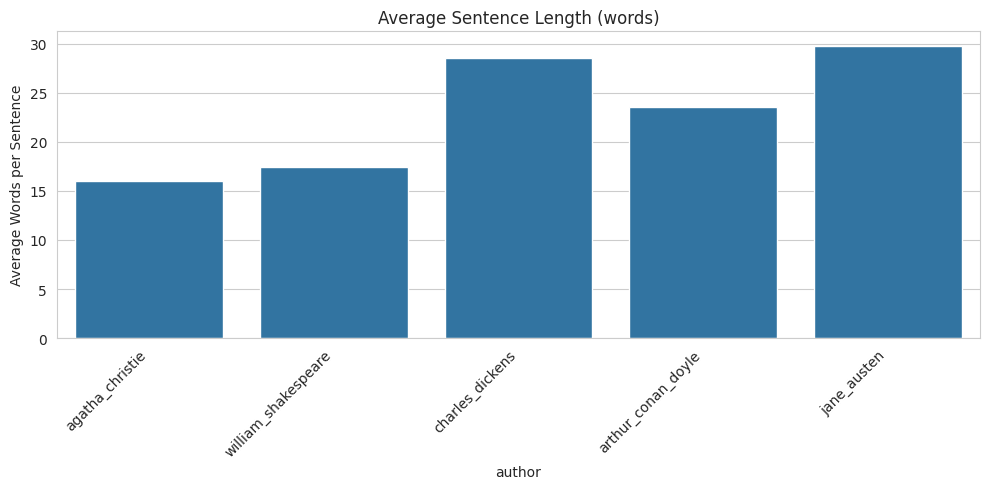

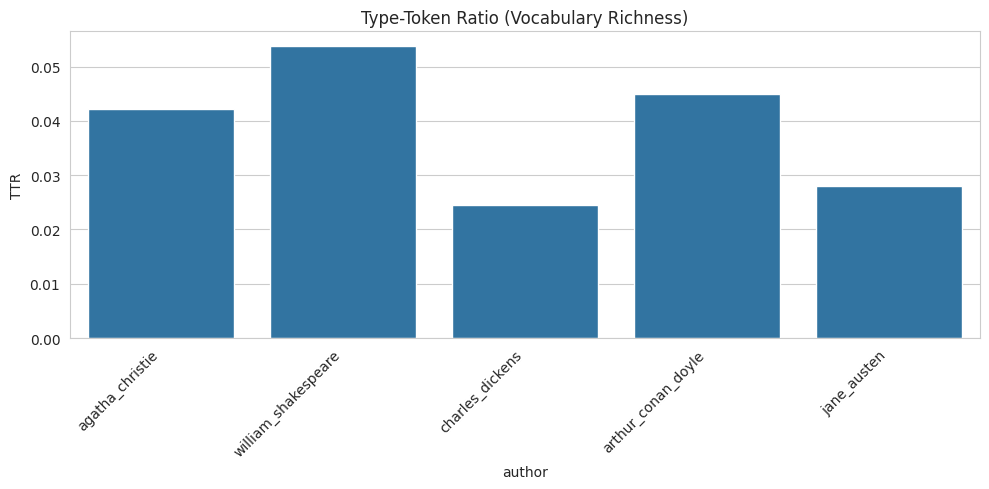

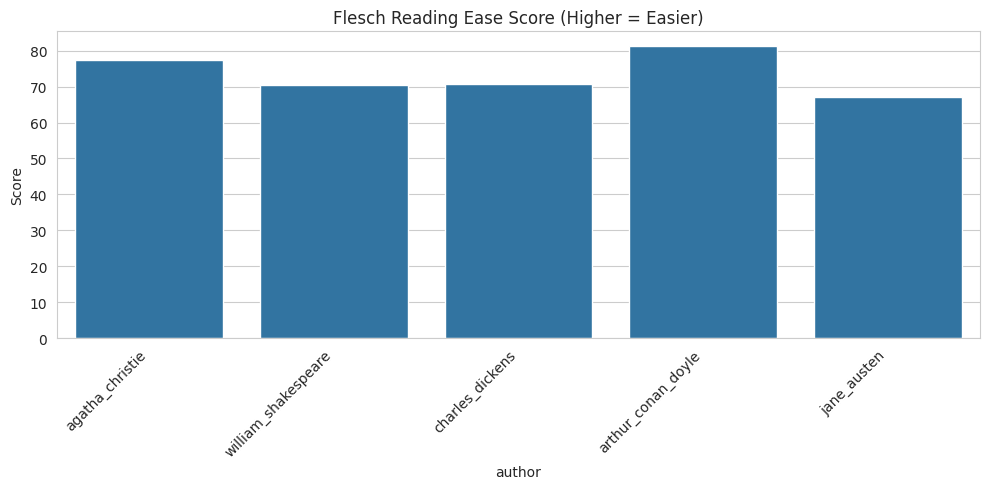

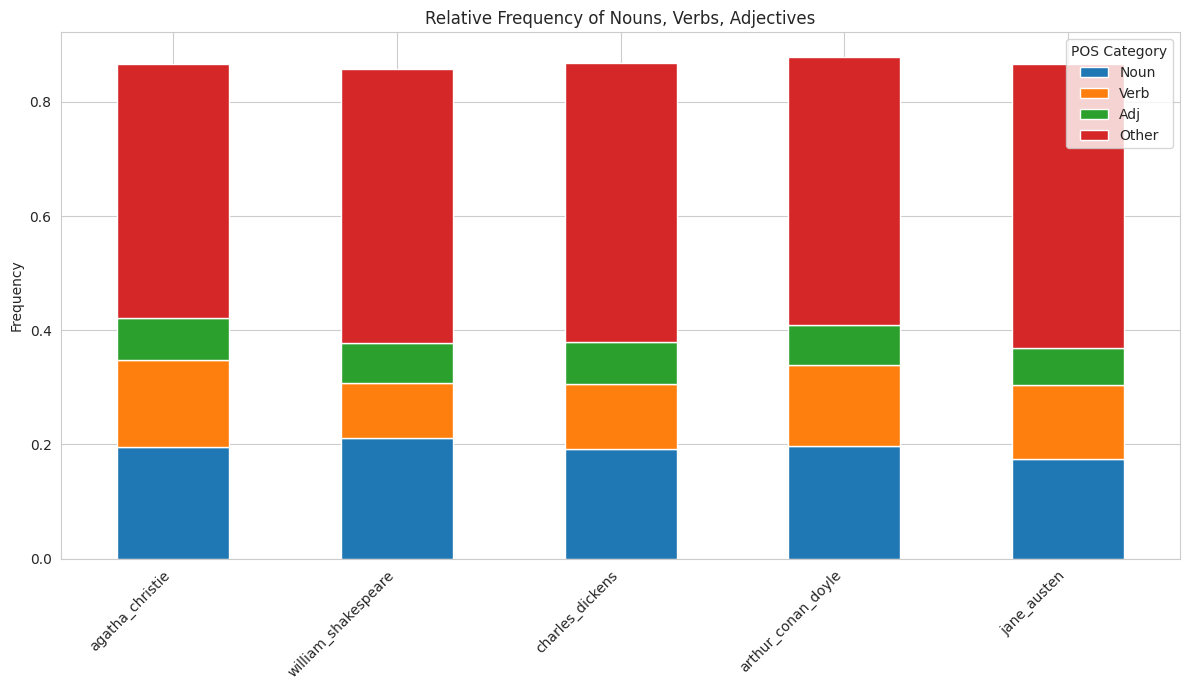

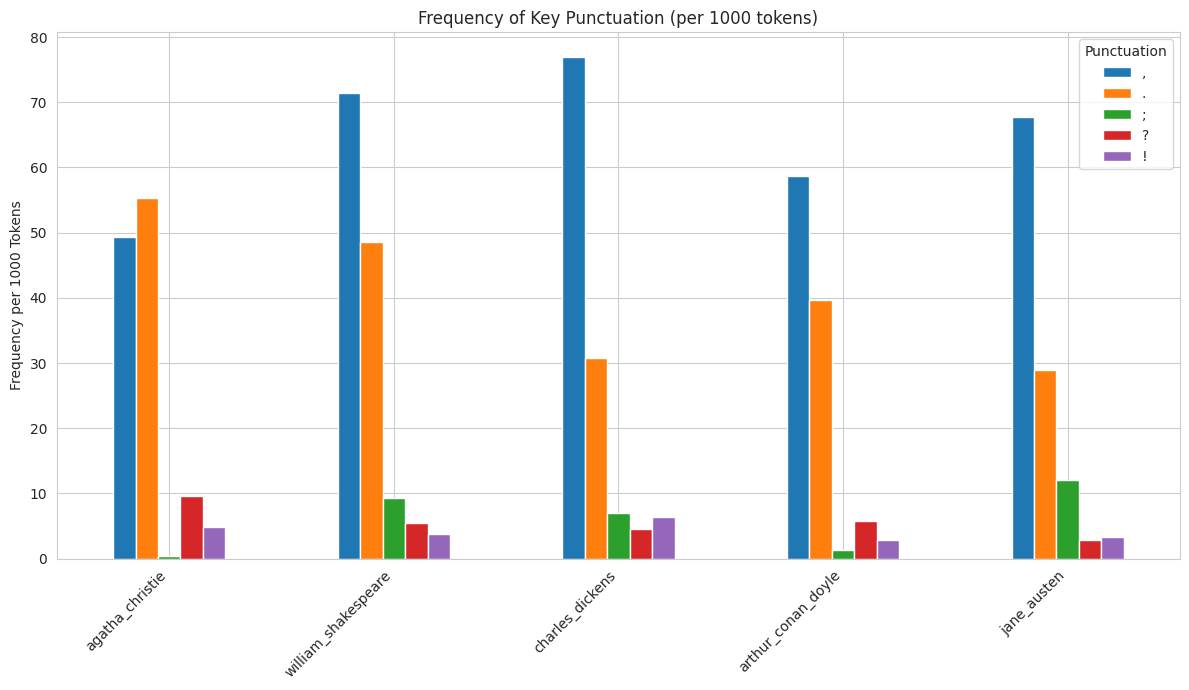

In [ ]:
# --- VISUALIZATIONS ---
sns.set_style("whitegrid")

# 1. Compare Average Sentence Length
plt.figure(figsize=(10, 5))
sns.barplot(x=df_analysis.index, y='avg_sent_len', data=df_analysis)
plt.title('Average Sentence Length (words)')
plt.ylabel('Average Words per Sentence')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 2. Compare Type-Token Ratio (Vocabulary Richness)
plt.figure(figsize=(10, 5))
sns.barplot(x=df_analysis.index, y='ttr', data=df_analysis)
plt.title('Type-Token Ratio (Vocabulary Richness)')
plt.ylabel('TTR')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Compare Readability (Flesch Reading Ease)
plt.figure(figsize=(10, 5))
sns.barplot(x=df_analysis.index, y='flesch_ease', data=df_analysis)
plt.title('Flesch Reading Ease Score (Higher = Easier)')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 4. Compare POS Tag Frequencies (Example: Nouns, Verbs, Adjectives)
# This requires processing the 'pos_freq' column which contains dictionaries

pos_comparison = {}
tags_to_compare = ['NN', 'NNS', 'NNP', 'NNPS', # Nouns
                   'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ', # Verbs
                   'JJ', 'JJR', 'JJS'] # Adjectives

for author in df_analysis.index:
    author_pos = df_analysis.loc[author, 'pos_freq']
    combined_tags = {
        'Noun': sum(author_pos.get(tag, 0) for tag in ['NN', 'NNS', 'NNP', 'NNPS']),
        'Verb': sum(author_pos.get(tag, 0) for tag in ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ']),
        'Adj': sum(author_pos.get(tag, 0) for tag in ['JJ', 'JJR', 'JJS']),
        'Other': sum(v for k, v in author_pos.items() if k not in tags_to_compare) # Rough 'Other' category
    }
    pos_comparison[author] = combined_tags

df_pos = pd.DataFrame.from_dict(pos_comparison, orient='index')

df_pos.plot(kind='bar', stacked=True, figsize=(12, 7))
plt.title('Relative Frequency of Nouns, Verbs, Adjectives')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.legend(title='POS Category')
plt.tight_layout()
plt.show()


# 5. Compare Punctuation Frequencies (Example: Comma, Period)
punct_comparison = {}
puncts_to_compare = [',', '.', ';', '?', '!']

for author in df_analysis.index:
    author_punct = df_analysis.loc[author, 'punct_freq']
    punct_data = {p: author_punct.get(p, 0) for p in puncts_to_compare}
    punct_comparison[author] = punct_data

df_punct = pd.DataFrame.from_dict(punct_comparison, orient='index')

df_punct.plot(kind='bar', figsize=(12, 7))
plt.title('Frequency of Key Punctuation (per 1000 tokens)')
plt.ylabel('Frequency per 1000 Tokens')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Punctuation')
plt.tight_layout()
plt.show()

### Plot 1: Average Sentence Length (words)

* **Observations:**
    * There is a distinct variation in average sentence length across the authors analyzed.
    * Jane Austen (~29.5 words) and Charles Dickens (~28.5 words) exhibit the longest average sentence lengths.
    * Agatha Christie (~16 words) has the shortest average sentence length, followed relatively closely by William Shakespeare (~17.5 words).
    * Arthur Conan Doyle (~23.5 words) falls in the middle range.

* **Interpretation:**
    * The significantly longer sentences used by **Austen** and **Dickens** are characteristic of much 19th-century prose. This often suggests more complex sentence structures, potentially involving multiple clauses, subordination, and elaborate descriptions or narrative exposition. It can contribute to a more formal tone and allow for detailed exploration of character thoughts or social settings.
    * The shorter sentences favoured by **Christie** likely contribute to the pacing and clarity often desired in mystery novels, potentially making the plot easier to follow and creating suspense through more direct statements.
    * **Shakespeare's** shorter average sentence length might be influenced by the nature of dramatic dialogue in plays, which often involves shorter, more direct exchanges compared to prose narration, alongside passages of verse.
    * **Doyle's** intermediate sentence length reflects a narrative style common in adventure and mystery stories, balancing descriptive passages with plot advancement.
    * This metric clearly distinguishes the more elaborate styles of Austen and Dickens from the more concise styles of Christie and Shakespeare within this corpus.

### Plot 2: Flesch Reading Ease Score (Higher = Easier)

* **Observations:**
    * Arthur Conan Doyle (~81) scores the highest, indicating his writing is considered the easiest to read among the group by this metric.
    * Agatha Christie (~77) also scores quite high, suggesting relatively easy readability.
    * William Shakespeare (~70) and Charles Dickens (~71) have similar, intermediate scores.
    * Jane Austen (~67) has the lowest score, indicating her writing is measured as the most complex or difficult to read in this set.

* **Interpretation:**
    * The Flesch Reading Ease score primarily considers average sentence length and average syllables per word. Higher scores generally correlate with shorter sentences and shorter words.
    * **Doyle's** top score aligns well with his moderate sentence length observed previously, suggesting straightforward sentence structure and likely common vocabulary, making his adventure narratives highly accessible.
    * **Christie's** high score is consistent with her short average sentence length, reinforcing the idea of clear, direct prose suitable for popular mystery fiction.
    * **Austen's** lowest score strongly correlates with her having the longest average sentences. This suggests her complex syntax and potentially more sophisticated vocabulary contribute significantly to the reading effort required, typical of literary fiction of her era.
    * **Dickens'** intermediate score is interesting given his very long sentences; it might imply that his word choices (syllables per word, not measured here) are not overly complex relative to his sentence length, or that the formula balances these aspects to place him in the middle range.
    * **Shakespeare's** score reflects a balance, possibly influenced by variations between prose, verse, dialogue, and vocabulary within his plays.
    * Overall, this metric reinforces the stylistic differences observed in sentence length, positioning Doyle and Christie as the most accessible writers in this group, and Austen as the most syntactically complex.

### Plot 3: Relative Frequency of Nouns, Verbs, Adjectives

* **Observations:**
    * The overall distribution of these broad Part-of-Speech (POS) categories (Noun, Verb, Adjective) is remarkably similar across all five authors. No single author shows a dramatically different profile at this high level.
    * The largest single portion for every author falls into the "Other" category (which includes pronouns, prepositions, adverbs, conjunctions, determiners, etc.), typically making up around 58-62% of the tokens. This is standard for English text.
    * Nouns consistently represent roughly 18-21% of the tokens.
    * Verbs make up approximately 12-16% of the tokens. Shakespeare shows a slightly lower proportion of verbs compared to nouns than the others.
    * Adjectives constitute the smallest portion of these three main categories, hovering around 6-7% for all authors.

* **Interpretation:**
    * The general similarity in these broad POS frequencies suggests that distinguishing these authors' styles likely requires looking at more granular features. While fundamental sentence building blocks are used in similar proportions, the *way* they are used differs.
    * The consistently large "Other" category highlights the importance of function words (prepositions, conjunctions, pronouns) in constructing sentences. Differences in how authors use these function words (e.g., frequency of specific prepositions, types of conjunctions used to link clauses) could be a significant stylistic marker not captured well by this high-level plot.
    * The relatively low and consistent use of adjectives suggests that none of these authors relies excessively on adjectives for description compared to others. Stylistic differences in description might come from noun/verb choice or sentence structure.
    * While subtle variations exist (e.g., Shakespeare's slightly lower verb proportion), these broad categories alone don't provide a strong distinguishing signal between these specific authors. Further analysis might involve looking at sub-categories (e.g., proper nouns vs common nouns, modal verbs vs main verbs) or syntactic patterns.

### Plot 4: Frequency of Key Punctuation (per 1000 tokens)

* **Observations:**
    * **Comma (`,`):** Charles Dickens uses commas most frequently, followed by Shakespeare and Jane Austen. Arthur Conan Doyle and Agatha Christie use them significantly less often.
    * **Period (`.`):** Agatha Christie shows the highest frequency of periods, followed by Shakespeare. Jane Austen and Charles Dickens have the lowest frequency. There appears to be a somewhat inverse relationship between comma and period frequency for several authors here.
    * **Semicolon (`;`):** Jane Austen stands out with markedly higher semicolon usage compared to all others. Shakespeare and Dickens show moderate use, while Doyle and Christie use them very infrequently.
    * **Question Mark (`?`):** Agatha Christie leads in question mark frequency, with Doyle and Shakespeare showing moderate usage. Austen and Dickens use them least.
    * **Exclamation Mark (`!`):** Charles Dickens has the highest frequency, followed by Agatha Christie. The other authors show relatively low usage.

* **Interpretation:**
    * **Sentence Complexity (Commas, Periods, Semicolons):** The punctuation patterns strongly correlate with the previously observed sentence lengths.
        * The high comma and low period usage in **Austen** and **Dickens** reinforces their tendency towards longer, more complex sentences with multiple clauses linked together. Austen's frequent use of semicolons further emphasizes a style that connects closely related independent clauses, often found in more formal or analytical prose.
        * **Christie's** high period and low comma/semicolon usage aligns perfectly with her shorter, more direct sentences, typical of plot-driven narratives.
        * **Shakespeare** and **Doyle** show intermediate patterns, consistent with their middle-ground sentence lengths.
    * **Dialogue and Genre (Question Marks):** The higher frequency of question marks in **Christie**, **Doyle**, and **Shakespeare** likely reflects a greater proportion of dialogue involving questions (investigations in mysteries, character interactions in plays and stories) compared to the more narrative or descriptive focus often seen in Austen and Dickens.
    * **Emphasis and Emotion (Exclamation Marks):** **Dickens'** higher use of exclamation marks may reflect the heightened emotional moments, dramatic emphasis, or specific character voices often present in his work. **Christie's** usage might relate to moments of revelation or suspense in the mystery genre. The lower usage by others suggests a more restrained textual expression of excitement or shock.
    * **Distinct Styles:** Punctuation serves as a strong differentiator. Austen's high semicolon use is unique here. The contrast between Austen/Dickens (complex sentences indicated by comma/period/semicolon patterns) and Christie (simpler sentences, more questions) is clearly visible.

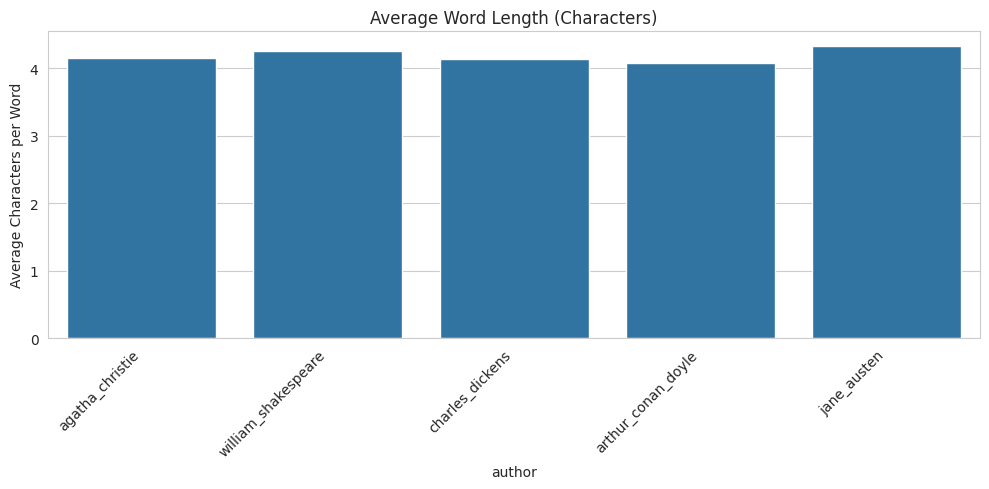

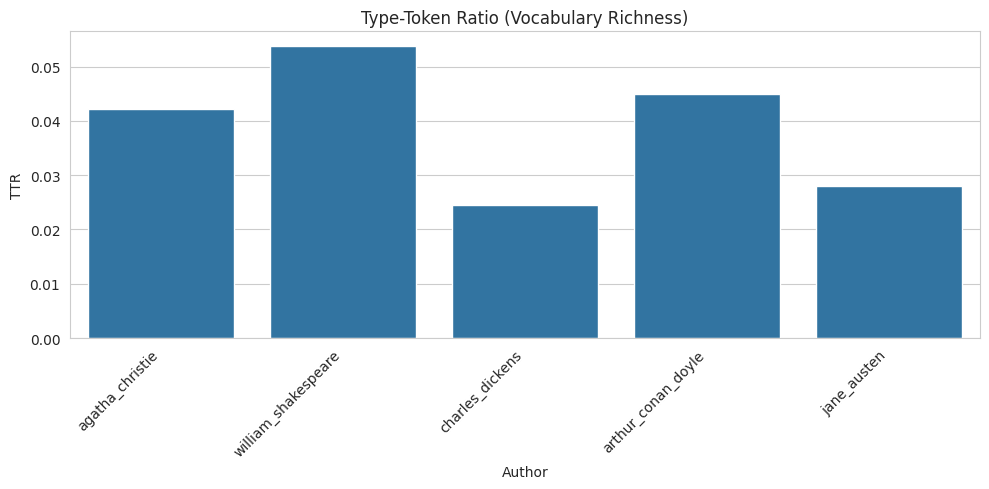

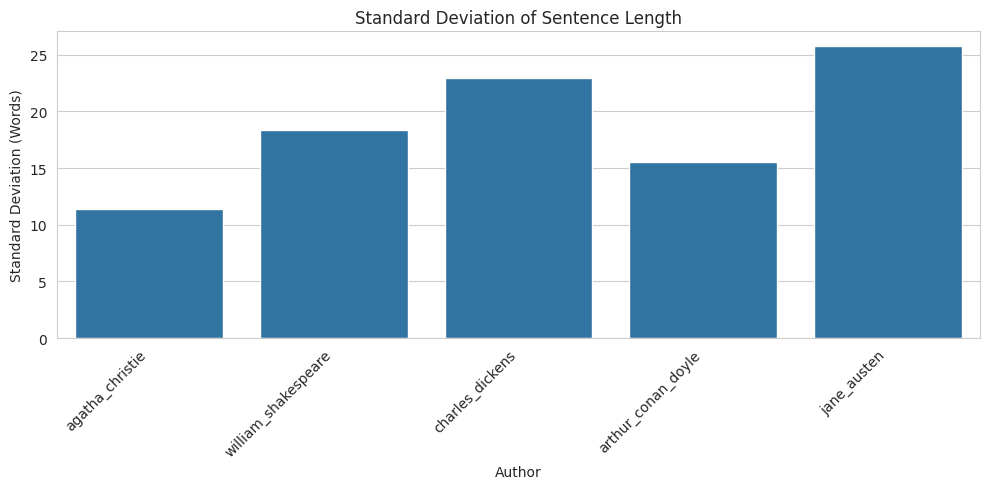

In [ ]:
# --- ADDITIONAL VISUALIZATIONS ---

# 6. Compare Average Word Length
plt.figure(figsize=(10, 5))
sns.barplot(x=df_analysis.index, y='avg_word_len', data=df_analysis)
plt.title('Average Word Length (Characters)')
plt.ylabel('Average Characters per Word')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 7. Compare Type-Token Ratio (TTR) - Already Plotted in Previous Answer Snippet, run if missed
# This plot was included in the first analysis code block I gave,
# but ensure it was run and check its results again for vocabulary richness.
plt.figure(figsize=(10, 5))
sns.barplot(x=df_analysis.index, y='ttr', data=df_analysis)
plt.title('Type-Token Ratio (Vocabulary Richness)')
plt.ylabel('TTR')
plt.xlabel('Author') # Added x-axis label for clarity
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# 8. (Optional) Compare Standard Deviation of Sentence Length
if 'std_sent_len' in df_analysis.columns: # Check if the column exists
    plt.figure(figsize=(10, 5))
    sns.barplot(x=df_analysis.index, y='std_sent_len', data=df_analysis)
    plt.title('Standard Deviation of Sentence Length')
    plt.ylabel('Standard Deviation (Words)')
    plt.xlabel('Author') # Added x-axis label
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("Standard deviation of sentence length ('std_sent_len') not found in DataFrame.")

### Plot 5: Average Word Length (Characters)

* **Observations:**
    * The average word length, measured in characters, is strikingly similar across all five authors. The values fall within a very narrow range (approximately 4.1 to 4.4 characters).
    * Jane Austen (~4.4) and William Shakespeare (~4.3) show a slightly higher average word length compared to the others.
    * Arthur Conan Doyle (~4.1) shows the slightly shortest average word length.
    * There are no significant outliers; no author uses dramatically longer or shorter words on average based on this metric.

* **Interpretation:**
    * This high degree of similarity suggests that the basic building blocks of vocabulary, in terms of average character count per word, don't vary drastically between these authors. Much of English text consists of shorter function words (the, a, is, in, etc.) and common nouns/verbs, which likely brings the overall average into a tight range for most prose writers.
    * The slightly longer average for Austen and Shakespeare *might* subtly indicate a tendency towards slightly more complex vocabulary or, in Shakespeare's case, perhaps different spelling conventions or word forms, but the difference is minimal.
    * Average word length in characters is a relatively simple metric. It doesn't directly measure polysyllabicity (number of syllables, which impacts readability more) or the semantic richness/rarity of the vocabulary.
    * Conclusion: Based on this plot, average word length in characters is **not** a strong distinguishing feature for the styles of these particular authors. Vocabulary differences are more likely to be found in the *variety* of words used (TTR) or the specific *choices* of words within similar length constraints.

### Plot 6: Type-Token Ratio (Vocabulary Richness)

* **Observations:**
    * There are clear differences in the Type-Token Ratios (TTR) among the authors.
    * William Shakespeare (~0.053) exhibits the highest TTR by a noticeable margin.
    * Charles Dickens (~0.025) has the lowest TTR, followed closely by Jane Austen (~0.028).
    * Arthur Conan Doyle (~0.045) and Agatha Christie (~0.042) have intermediate TTR values, relatively close to each other.

* **Interpretation:**
    * TTR measures the ratio of unique words (types) to the total number of words (tokens). A higher TTR generally indicates greater lexical diversity, meaning a larger proportion of the words used are unique.
    * **Shakespeare's** high TTR aligns with his renowned large vocabulary and linguistic creativity, suggesting he uses a wider range of unique words relative to the overall length of his texts compared to the others in this set.
    * The significantly lower TTR for **Dickens** and **Austen** suggests less lexical diversity *in proportion to the total text volume*. This could mean they rely more on repeating a core set of vocabulary throughout their extensive narratives, or it could be influenced by the overall length of their corpora (TTR tends to decrease as text length increases because common words inevitably get repeated more often). It doesn't necessarily imply a smaller absolute vocabulary, but rather that unique words make up a smaller fraction of their total word count here.
    * **Doyle** and **Christie's** moderate TTR suggests a balanced vocabulary, likely sufficient for descriptive narration and dialogue in genre fiction without being as lexically dense (proportionally) as Shakespeare or as repetitive (proportionally) as Dickens/Austen in this analysis.
    * **Important Note:** Basic TTR is sensitive to the total length of the text analyzed. If the corpus sizes are very different, it can skew comparisons. However, the observed differences, especially between Shakespeare and Dickens/Austen, are quite pronounced and likely reflect genuine stylistic tendencies in vocabulary usage within this dataset.
    * TTR provides a valuable metric for distinguishing the authors based on vocabulary variety.

### Plot 7: Standard Deviation of Sentence Length (Words)

* **Observations:**
    * Jane Austen (~25.5 words) exhibits the highest standard deviation by a noticeable margin, indicating the greatest variability in sentence lengths within her texts.
    * Charles Dickens (~23 words) also shows a high degree of variability, second only to Austen.
    * Agatha Christie (~11.5 words) has the lowest standard deviation, suggesting her sentence lengths are the most consistent around her average.
    * Arthur Conan Doyle (~15.5 words) also displays relatively low variability.
    * William Shakespeare (~18 words) falls into the middle range for sentence length variation.

* **Interpretation:**
    * Standard deviation measures the spread or dispersion of sentence lengths. A high value means an author uses a wide mix of short and long sentences, while a low value indicates most sentences are close to the author's average length.
    * **High Variability (Austen, Dickens):** Combined with their long *average* sentence lengths, the high standard deviation for Austen and Dickens suggests a highly dynamic style. They don't just write long sentences; they likely employ a broad spectrum of lengths, perhaps using very long descriptive or narrative sentences interspersed with shorter ones for dialogue or emphasis. This variability can create a complex rhythm.
    * **Low Variability (Christie, Doyle):** These authors demonstrate more consistency. Christie's very low standard deviation, combined with her short average length, points to a very steady, predictable rhythm dominated by short, direct sentences – ideal for clarity and pacing in mysteries. Doyle's relatively low variability around a moderate average length suggests a dependable, even narrative flow.
    * **Moderate Variability (Shakespeare):** Shakespeare's middle position likely reflects the mixed nature of plays – containing dialogue, soliloquies, prose, and verse, leading to more sentence length variation than Christie/Doyle but perhaps less than the sprawling narrative prose of Austen/Dickens.
    * **Overall:** This metric differentiates authors based on the *consistency* of their sentence structuring. It clearly contrasts the dynamic range of Austen and Dickens with the more uniform pacing of Christie and Doyle.

In [ ]:
!pip install transformers datasets torch accelerate -U
# 'accelerate' helps optimize training on available hardware (CPU/GPU)
# 'torch' is the PyTorch backend, commonly used with transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 118.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 78.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 56.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 90.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import nltk
try:
    nltk.data.find('tokenizers/punkt')
    nltk.data.find('taggers/averaged_perceptron_tagger')
    print("NLTK data found.")
except LookupError:
    print("Downloading NLTK data...")
    nltk.download('punkt')
    nltk.download('averaged_perceptron_tagger')

NLTK data found.


In [ ]:
import os
import torch # etc... other standard imports
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments
from google.colab import data_table # For nice dataframe display
data_table.enable_dataframe_formatter()

# *** SET YOUR BASE PROJECT PATH IN DRIVE ***
BASE_DRIVE_PATH = "/content/drive/MyDrive/Writing_Style_Mimic" # Adjust if needed
DATA_PROCESSED_DIR = os.path.join(BASE_DRIVE_PATH, "data/processed")
MODELS_BASE_DIR = os.path.join(BASE_DRIVE_PATH, "models")

print("Imports done, paths set.")

Imports done, paths set.


In [ ]:
from transformers import AutoTokenizer

model_checkpoint = "gpt2" # Using the base GPT-2 model
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, use_fast=True)
tokenizer.pad_token = tokenizer.eos_token # <-- *** ADD THIS LINE ***
print(f"Tokenizer for {model_checkpoint} loaded. Pad token set to EOS token ({tokenizer.pad_token}).")

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizer for gpt2 loaded. Pad token set to EOS token (<|endoftext|>).


In [ ]:
# *** CHANGE THIS FOR EACH AUTHOR ***
author_name = "jane_austen" # e.g., next time: "charles_dickens"

# Define author-specific paths
author_processed_file = os.path.join(DATA_PROCESSED_DIR, author_name, "corpus.txt")
author_output_dir = os.path.join(MODELS_BASE_DIR, f"{author_name}_gpt2_finetuned")
author_final_model_path = os.path.join(MODELS_BASE_DIR, f"{author_name}_final")

print(f"--- Processing Author: {author_name} ---")
print(f"Processed data path: {author_processed_file}")
print(f"Training output dir: {author_output_dir}")
print(f"Final model save path: {author_final_model_path}")

# Define block size for this author's training run
block_size = 128

--- Processing Author: jane_austen ---
Processed data path: /content/drive/MyDrive/Writing_Style_Mimic/data/processed/jane_austen/corpus.txt
Training output dir: /content/drive/MyDrive/Writing_Style_Mimic/models/jane_austen_gpt2_finetuned
Final model save path: /content/drive/MyDrive/Writing_Style_Mimic/models/jane_austen_final


In [ ]:
if not os.path.exists(author_processed_file):
    print(f"ERROR: Processed file not found for {author_name} at {author_processed_file}")
else:
    data_files = {"train": author_processed_file}
    raw_datasets = load_dataset("text", data_files=data_files)
    print(f"Loaded dataset for {author_name}: {raw_datasets}")

Generating train split: 0 examples [00:00, ? examples/s]

Loaded dataset for jane_austen: DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 17474
    })
})


In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, num_proc=1, remove_columns=["text"])
print(f"Tokenized dataset sample: {tokenized_datasets['train'][0]['input_ids'][:50]}...")

Map:   0%|          | 0/17474 [00:00<?, ? examples/s]

Tokenized dataset sample: [43588, 2564, 450, 23454, 416, 474, 1531, 38132, 268, 357, 1248, 3070, 1267, 10154, 15422, 416, 262, 6284, 382, 824, 837, 284, 5093, 2564, 450, 23454, 6843, 352, 6843, 362, 6843, 513, 6843, 604, 6843, 642, 6843, 718, 6843, 767, 6843, 807, 6843, 860, 6843, 838, 6843, 1367, 6843, 1105]...


In [ ]:
def group_texts(examples):
    concatenated_examples = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // block_size) * block_size
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    result["labels"] = result["input_ids"].copy()
    return result

lm_datasets = tokenized_datasets.map(group_texts, batched=True, batch_size=1000, num_proc=1)
print(f"Processed dataset into blocks. Example block length: {len(lm_datasets['train'][0]['input_ids'])}")

Map:   0%|          | 0/17474 [00:00<?, ? examples/s]

Processed dataset into blocks. Example block length: 128


In [ ]:
try:
  # Only run split if dataset is large enough
  if len(lm_datasets['train']) > 10: # Basic check
      train_test_split = lm_datasets['train'].train_test_split(test_size=0.1)
      final_datasets = train_test_split
      print(f"Split dataset: {final_datasets}")
  else:
      print("Dataset too small to split, using full dataset for training.")
      final_datasets = lm_datasets # Use the whole thing for training
      # Ensure the key is 'train' for the Trainer
      if 'train' not in final_datasets:
         final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

except Exception as e:
    print(f"Could not split dataset, using full dataset for training. Error: {e}")
    final_datasets = lm_datasets # Fallback
    if 'train' not in final_datasets:
       final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

Split dataset: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 4070
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 453
    })
})


In [ ]:
# *** Load a fresh copy of the base model for EACH author ***
model = AutoModelForCausalLM.from_pretrained(model_checkpoint)
print(f"Loaded fresh pre-trained {model_checkpoint} model.")

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Loaded fresh pre-trained gpt2 model.


In [ ]:
training_args = TrainingArguments(
    output_dir=author_output_dir, # Author-specific output
    eval_strategy="epoch" if "test" in final_datasets else "no", # Evaluate if split succeeded
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=3, # Adjust as needed
    per_device_train_batch_size=4, # Adjust based on GPU memory
    per_device_eval_batch_size=4,
    save_strategy="epoch",
    logging_steps=100,
    # load_best_model_at_end=True if "test" in final_datasets else False, # Only if evaluating
    # metric_for_best_model = "loss" if "test" in final_datasets else None, # Only if evaluating
    # greater_is_better = False, # For loss
)
print("Training arguments defined.")

Training arguments defined.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=final_datasets["train"],
    eval_dataset=final_datasets.get("test"), # Use .get() in case 'test' key doesn't exist
    tokenizer=tokenizer,
)
print("Trainer instantiated.")

<ipython-input-21-d8d8e70018ae>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Trainer instantiated.


In [ ]:
print(f"--- Starting fine-tuning for {author_name}... ---")
trainer.train()
print(f"--- Fine-tuning finished for {author_name}. ---")

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


--- Starting fine-tuning for jane_austen... ---


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: vinay2004y (vinay2004y-mit-world-peace-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,3.494200,3.421654
2,3.386000,3.368942
3,3.288900,3.356104


--- Fine-tuning finished for jane_austen. ---


In [ ]:
print(f"--- Saving final model for {author_name} to {author_final_model_path}... ---")
trainer.save_model(author_final_model_path)
# tokenizer.save_pretrained(author_final_model_path) # Already passed to Trainer, should be saved automatically
print(f"--- Model for {author_name} saved. ---")

# Optional: Clear memory if running many authors in one session
# import torch
# del model
# del trainer
# torch.cuda.empty_cache()
# print("Cleared memory (optional).")

--- Saving final model for jane_austen to /content/drive/MyDrive/Writing_Style_Mimic/models/jane_austen_final... ---
--- Model for jane_austen saved. ---


In [ ]:
# *** CHANGE THIS FOR EACH AUTHOR ***
author_name = "william_shakespeare" # e.g., next time: "charles_dickens"

# Define author-specific paths
author_processed_file = os.path.join(DATA_PROCESSED_DIR, author_name, "corpus.txt")
author_output_dir = os.path.join(MODELS_BASE_DIR, f"{author_name}_gpt2_finetuned")
author_final_model_path = os.path.join(MODELS_BASE_DIR, f"{author_name}_final")

print(f"--- Processing Author: {author_name} ---")
print(f"Processed data path: {author_processed_file}")
print(f"Training output dir: {author_output_dir}")
print(f"Final model save path: {author_final_model_path}")

# Define block size for this author's training run
block_size = 128

--- Processing Author: william_shakespeare ---
Processed data path: /content/drive/MyDrive/Writing_Style_Mimic/data/processed/william_shakespeare/corpus.txt
Training output dir: /content/drive/MyDrive/Writing_Style_Mimic/models/william_shakespeare_gpt2_finetuned
Final model save path: /content/drive/MyDrive/Writing_Style_Mimic/models/william_shakespeare_final


In [ ]:
if not os.path.exists(author_processed_file):
    print(f"ERROR: Processed file not found for {author_name} at {author_processed_file}")
else:
    data_files = {"train": author_processed_file}
    raw_datasets = load_dataset("text", data_files=data_files)
    print(f"Loaded dataset for {author_name}: {raw_datasets}")

Generating train split: 0 examples [00:00, ? examples/s]

Loaded dataset for william_shakespeare: DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 19331
    })
})


In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, num_proc=1, remove_columns=["text"])
print(f"Tokenized dataset sample: {tokenized_datasets['train'][0]['input_ids'][:50]}...")

Map:   0%|          | 0/19331 [00:00<?, ? examples/s]

Tokenized dataset sample: [32783, 416, 424, 38395, 7582, 837, 300, 9160, 302, 47709, 290, 262, 2691, 9387, 6617, 25782, 1074, 379, 3740, 1058, 3373, 2503, 13, 6024, 26059, 13, 3262, 427, 20946, 272, 13574, 8352, 17805, 272, 290, 763, 13, 837, 3614, 300, 3391, 27657, 323, 9948, 8968, 83, 321, 41909, 8597, 417]...


In [ ]:
def group_texts(examples):
    concatenated_examples = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // block_size) * block_size
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    result["labels"] = result["input_ids"].copy()
    return result

lm_datasets = tokenized_datasets.map(group_texts, batched=True, batch_size=1000, num_proc=1)
print(f"Processed dataset into blocks. Example block length: {len(lm_datasets['train'][0]['input_ids'])}")

Map:   0%|          | 0/19331 [00:00<?, ? examples/s]

Processed dataset into blocks. Example block length: 128


In [ ]:
try:
  # Only run split if dataset is large enough
  if len(lm_datasets['train']) > 10: # Basic check
      train_test_split = lm_datasets['train'].train_test_split(test_size=0.1)
      final_datasets = train_test_split
      print(f"Split dataset: {final_datasets}")
  else:
      print("Dataset too small to split, using full dataset for training.")
      final_datasets = lm_datasets # Use the whole thing for training
      # Ensure the key is 'train' for the Trainer
      if 'train' not in final_datasets:
         final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

except Exception as e:
    print(f"Could not split dataset, using full dataset for training. Error: {e}")
    final_datasets = lm_datasets # Fallback
    if 'train' not in final_datasets:
       final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

Split dataset: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2735
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 304
    })
})


In [ ]:
# *** Load a fresh copy of the base model for EACH author ***
model = AutoModelForCausalLM.from_pretrained(model_checkpoint)
print(f"Loaded fresh pre-trained {model_checkpoint} model.")

Loaded fresh pre-trained gpt2 model.


In [ ]:
training_args = TrainingArguments(
    output_dir=author_output_dir, # Author-specific output
    eval_strategy="epoch" if "test" in final_datasets else "no", # Evaluate if split succeeded
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=3, # Adjust as needed
    per_device_train_batch_size=4, # Adjust based on GPU memory
    per_device_eval_batch_size=4,
    save_strategy="epoch",
    logging_steps=100,
    # load_best_model_at_end=True if "test" in final_datasets else False, # Only if evaluating
    # metric_for_best_model = "loss" if "test" in final_datasets else None, # Only if evaluating
    # greater_is_better = False, # For loss
)
print("Training arguments defined.")

Training arguments defined.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=final_datasets["train"],
    eval_dataset=final_datasets.get("test"), # Use .get() in case 'test' key doesn't exist
    tokenizer=tokenizer,
)
print("Trainer instantiated.")

<ipython-input-32-d8d8e70018ae>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Trainer instantiated.


In [ ]:
print(f"--- Starting fine-tuning for {author_name}... ---")
trainer.train()
print(f"--- Fine-tuning finished for {author_name}. ---")

--- Starting fine-tuning for william_shakespeare... ---


Epoch,Training Loss,Validation Loss
1,3.878200,3.855374
2,3.735600,3.788294
3,3.654400,3.772725


--- Fine-tuning finished for william_shakespeare. ---


In [ ]:
print(f"--- Saving final model for {author_name} to {author_final_model_path}... ---")
trainer.save_model(author_final_model_path)
# tokenizer.save_pretrained(author_final_model_path) # Already passed to Trainer, should be saved automatically
print(f"--- Model for {author_name} saved. ---")

# Optional: Clear memory if running many authors in one session
# import torch
# del model
# del trainer
# torch.cuda.empty_cache()
# print("Cleared memory (optional).")

--- Saving final model for william_shakespeare to /content/drive/MyDrive/Writing_Style_Mimic/models/william_shakespeare_final... ---
--- Model for william_shakespeare saved. ---


In [ ]:
# *** CHANGE THIS FOR EACH AUTHOR ***
author_name = "charles_dickens" # e.g., next time: "charles_dickens"

# Define author-specific paths
author_processed_file = os.path.join(DATA_PROCESSED_DIR, author_name, "corpus.txt")
author_output_dir = os.path.join(MODELS_BASE_DIR, f"{author_name}_gpt2_finetuned")
author_final_model_path = os.path.join(MODELS_BASE_DIR, f"{author_name}_final")

print(f"--- Processing Author: {author_name} ---")
print(f"Processed data path: {author_processed_file}")
print(f"Training output dir: {author_output_dir}")
print(f"Final model save path: {author_final_model_path}")

# Define block size for this author's training run
block_size = 128

--- Processing Author: charles_dickens ---
Processed data path: /content/drive/MyDrive/Writing_Style_Mimic/data/processed/charles_dickens/corpus.txt
Training output dir: /content/drive/MyDrive/Writing_Style_Mimic/models/charles_dickens_gpt2_finetuned
Final model save path: /content/drive/MyDrive/Writing_Style_Mimic/models/charles_dickens_final


In [ ]:
if not os.path.exists(author_processed_file):
    print(f"ERROR: Processed file not found for {author_name} at {author_processed_file}")
else:
    data_files = {"train": author_processed_file}
    raw_datasets = load_dataset("text", data_files=data_files)
    print(f"Loaded dataset for {author_name}: {raw_datasets}")

Generating train split: 0 examples [00:00, ? examples/s]

Loaded dataset for charles_dickens: DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 43393
    })
})


In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, num_proc=1, remove_columns=["text"])
print(f"Tokenized dataset sample: {tokenized_datasets['train'][0]['input_ids'][:50]}...")

Map:   0%|          | 0/43393 [00:00<?, ? examples/s]

Tokenized dataset sample: [67, 8490, 15317, 3245, 416, 1149, 829, 19317, 641, 17696, 1286, 45100, 284, 262, 3032, 764]...


In [ ]:
def group_texts(examples):
    concatenated_examples = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // block_size) * block_size
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    result["labels"] = result["input_ids"].copy()
    return result

lm_datasets = tokenized_datasets.map(group_texts, batched=True, batch_size=1000, num_proc=1)
print(f"Processed dataset into blocks. Example block length: {len(lm_datasets['train'][0]['input_ids'])}")

Map:   0%|          | 0/43393 [00:00<?, ? examples/s]

Processed dataset into blocks. Example block length: 128


In [ ]:
try:
  # Only run split if dataset is large enough
  if len(lm_datasets['train']) > 10: # Basic check
      train_test_split = lm_datasets['train'].train_test_split(test_size=0.1)
      final_datasets = train_test_split
      print(f"Split dataset: {final_datasets}")
  else:
      print("Dataset too small to split, using full dataset for training.")
      final_datasets = lm_datasets # Use the whole thing for training
      # Ensure the key is 'train' for the Trainer
      if 'train' not in final_datasets:
         final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

except Exception as e:
    print(f"Could not split dataset, using full dataset for training. Error: {e}")
    final_datasets = lm_datasets # Fallback
    if 'train' not in final_datasets:
       final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

Split dataset: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 10053
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1118
    })
})


In [ ]:
# *** Load a fresh copy of the base model for EACH author ***
model = AutoModelForCausalLM.from_pretrained(model_checkpoint)
print(f"Loaded fresh pre-trained {model_checkpoint} model.")

Loaded fresh pre-trained gpt2 model.


In [ ]:
training_args = TrainingArguments(
    output_dir=author_output_dir, # Author-specific output
    eval_strategy="epoch" if "test" in final_datasets else "no", # Evaluate if split succeeded
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=3, # Adjust as needed
    per_device_train_batch_size=4, # Adjust based on GPU memory
    per_device_eval_batch_size=4,
    save_strategy="epoch",
    logging_steps=100,
    # load_best_model_at_end=True if "test" in final_datasets else False, # Only if evaluating
    # metric_for_best_model = "loss" if "test" in final_datasets else None, # Only if evaluating
    # greater_is_better = False, # For loss
)
print("Training arguments defined.")

Training arguments defined.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=final_datasets["train"],
    eval_dataset=final_datasets.get("test"), # Use .get() in case 'test' key doesn't exist
    tokenizer=tokenizer,
)
print("Trainer instantiated.")

<ipython-input-42-d8d8e70018ae>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Trainer instantiated.


In [ ]:
print(f"--- Starting fine-tuning for {author_name}... ---")
trainer.train()
print(f"--- Fine-tuning finished for {author_name}. ---")

--- Starting fine-tuning for charles_dickens... ---


Epoch,Training Loss,Validation Loss
1,3.339400,3.256413
2,3.199100,3.211059
3,3.201100,3.198848


--- Fine-tuning finished for charles_dickens. ---


In [ ]:
print(f"--- Saving final model for {author_name} to {author_final_model_path}... ---")
trainer.save_model(author_final_model_path)
# tokenizer.save_pretrained(author_final_model_path) # Already passed to Trainer, should be saved automatically
print(f"--- Model for {author_name} saved. ---")

# Optional: Clear memory if running many authors in one session
# import torch
# del model
# del trainer
# torch.cuda.empty_cache()
# print("Cleared memory (optional).")

--- Saving final model for charles_dickens to /content/drive/MyDrive/Writing_Style_Mimic/models/charles_dickens_final... ---
--- Model for charles_dickens saved. ---


In [ ]:
# *** CHANGE THIS FOR EACH AUTHOR ***
author_name = "arthur_conan_doyle" # e.g., next time: "charles_dickens"

# Define author-specific paths
author_processed_file = os.path.join(DATA_PROCESSED_DIR, author_name, "corpus.txt")
author_output_dir = os.path.join(MODELS_BASE_DIR, f"{author_name}_gpt2_finetuned")
author_final_model_path = os.path.join(MODELS_BASE_DIR, f"{author_name}_final")

print(f"--- Processing Author: {author_name} ---")
print(f"Processed data path: {author_processed_file}")
print(f"Training output dir: {author_output_dir}")
print(f"Final model save path: {author_final_model_path}")

# Define block size for this author's training run
block_size = 128

--- Processing Author: arthur_conan_doyle ---
Processed data path: /content/drive/MyDrive/Writing_Style_Mimic/data/processed/arthur_conan_doyle/corpus.txt
Training output dir: /content/drive/MyDrive/Writing_Style_Mimic/models/arthur_conan_doyle_gpt2_finetuned
Final model save path: /content/drive/MyDrive/Writing_Style_Mimic/models/arthur_conan_doyle_final


In [ ]:
if not os.path.exists(author_processed_file):
    print(f"ERROR: Processed file not found for {author_name} at {author_processed_file}")
else:
    data_files = {"train": author_processed_file}
    raw_datasets = load_dataset("text", data_files=data_files)
    print(f"Loaded dataset for {author_name}: {raw_datasets}")

Generating train split: 0 examples [00:00, ? examples/s]

Loaded dataset for arthur_conan_doyle: DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 15690
    })
})


In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, num_proc=1, remove_columns=["text"])
print(f"Tokenized dataset sample: {tokenized_datasets['train'][0]['input_ids'][:50]}...")

Map:   0%|          | 0/15690 [00:00<?, ? examples/s]

Tokenized dataset sample: [1169, 1051, 286, 262, 1440, 416, 610, 11098, 369, 272, 466, 2349, 10154, 6843, 1312, 764]...


In [ ]:
def group_texts(examples):
    concatenated_examples = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // block_size) * block_size
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    result["labels"] = result["input_ids"].copy()
    return result

lm_datasets = tokenized_datasets.map(group_texts, batched=True, batch_size=1000, num_proc=1)
print(f"Processed dataset into blocks. Example block length: {len(lm_datasets['train'][0]['input_ids'])}")

Map:   0%|          | 0/15690 [00:00<?, ? examples/s]

Processed dataset into blocks. Example block length: 128


In [ ]:
try:
  # Only run split if dataset is large enough
  if len(lm_datasets['train']) > 10: # Basic check
      train_test_split = lm_datasets['train'].train_test_split(test_size=0.1)
      final_datasets = train_test_split
      print(f"Split dataset: {final_datasets}")
  else:
      print("Dataset too small to split, using full dataset for training.")
      final_datasets = lm_datasets # Use the whole thing for training
      # Ensure the key is 'train' for the Trainer
      if 'train' not in final_datasets:
         final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

except Exception as e:
    print(f"Could not split dataset, using full dataset for training. Error: {e}")
    final_datasets = lm_datasets # Fallback
    if 'train' not in final_datasets:
       final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

Split dataset: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 2966
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 330
    })
})


In [ ]:
# *** Load a fresh copy of the base model for EACH author ***
model = AutoModelForCausalLM.from_pretrained(model_checkpoint)
print(f"Loaded fresh pre-trained {model_checkpoint} model.")

Loaded fresh pre-trained gpt2 model.


In [ ]:
training_args = TrainingArguments(
    output_dir=author_output_dir, # Author-specific output
    eval_strategy="epoch" if "test" in final_datasets else "no", # Evaluate if split succeeded
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=3, # Adjust as needed
    per_device_train_batch_size=4, # Adjust based on GPU memory
    per_device_eval_batch_size=4,
    save_strategy="epoch",
    logging_steps=100,
    # load_best_model_at_end=True if "test" in final_datasets else False, # Only if evaluating
    # metric_for_best_model = "loss" if "test" in final_datasets else None, # Only if evaluating
    # greater_is_better = False, # For loss
)
print("Training arguments defined.")

Training arguments defined.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=final_datasets["train"],
    eval_dataset=final_datasets.get("test"), # Use .get() in case 'test' key doesn't exist
    tokenizer=tokenizer,
)
print("Trainer instantiated.")

<ipython-input-52-d8d8e70018ae>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Trainer instantiated.


In [ ]:
print(f"--- Starting fine-tuning for {author_name}... ---")
trainer.train()
print(f"--- Fine-tuning finished for {author_name}. ---")

--- Starting fine-tuning for arthur_conan_doyle... ---


Epoch,Training Loss,Validation Loss
1,3.303300,3.235895
2,3.150700,3.187011
3,3.104900,3.178068


--- Fine-tuning finished for arthur_conan_doyle. ---


In [ ]:
print(f"--- Saving final model for {author_name} to {author_final_model_path}... ---")
trainer.save_model(author_final_model_path)
# tokenizer.save_pretrained(author_final_model_path) # Already passed to Trainer, should be saved automatically
print(f"--- Model for {author_name} saved. ---")

# Optional: Clear memory if running many authors in one session
# import torch
# del model
# del trainer
# torch.cuda.empty_cache()
# print("Cleared memory (optional).")

--- Saving final model for arthur_conan_doyle to /content/drive/MyDrive/Writing_Style_Mimic/models/arthur_conan_doyle_final... ---
--- Model for arthur_conan_doyle saved. ---


In [ ]:
# *** CHANGE THIS FOR EACH AUTHOR ***
author_name = "agatha_christie" # e.g., next time: "charles_dickens"

# Define author-specific paths
author_processed_file = os.path.join(DATA_PROCESSED_DIR, author_name, "corpus.txt")
author_output_dir = os.path.join(MODELS_BASE_DIR, f"{author_name}_gpt2_finetuned")
author_final_model_path = os.path.join(MODELS_BASE_DIR, f"{author_name}_final")

print(f"--- Processing Author: {author_name} ---")
print(f"Processed data path: {author_processed_file}")
print(f"Training output dir: {author_output_dir}")
print(f"Final model save path: {author_final_model_path}")

# Define block size for this author's training run
block_size = 128

--- Processing Author: agatha_christie ---
Processed data path: /content/drive/MyDrive/Writing_Style_Mimic/data/processed/agatha_christie/corpus.txt
Training output dir: /content/drive/MyDrive/Writing_Style_Mimic/models/agatha_christie_gpt2_finetuned
Final model save path: /content/drive/MyDrive/Writing_Style_Mimic/models/agatha_christie_final


In [ ]:
if not os.path.exists(author_processed_file):
    print(f"ERROR: Processed file not found for {author_name} at {author_processed_file}")
else:
    data_files = {"train": author_processed_file}
    raw_datasets = load_dataset("text", data_files=data_files)
    print(f"Loaded dataset for {author_name}: {raw_datasets}")

Generating train split: 0 examples [00:00, ? examples/s]

Loaded dataset for agatha_christie: DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 26580
    })
})


In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"])

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, num_proc=1, remove_columns=["text"])
print(f"Tokenized dataset sample: {tokenized_datasets['train'][0]['input_ids'][:50]}...")

Map:   0%|          | 0/26580 [00:00<?, ? examples/s]

Tokenized dataset sample: [7501, 7058, 83, 44846, 416, 262, 976, 1772, 262, 11428, 14669, 379, 12186, 262, 3200, 34114, 262, 5123, 319, 262, 6117, 262, 16429, 1636, 1182, 745, 7058, 83, 44846, 416, 556, 30921, 33826, 494, 300, 3391, 45610, 11193, 262, 16429, 1636, 1182, 3614, 717, 3199, 287, 1049, 275, 799, 391]...


In [ ]:
def group_texts(examples):
    concatenated_examples = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // block_size) * block_size
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    result["labels"] = result["input_ids"].copy()
    return result

lm_datasets = tokenized_datasets.map(group_texts, batched=True, batch_size=1000, num_proc=1)
print(f"Processed dataset into blocks. Example block length: {len(lm_datasets['train'][0]['input_ids'])}")

Map:   0%|          | 0/26580 [00:00<?, ? examples/s]

Processed dataset into blocks. Example block length: 128


In [ ]:
try:
  # Only run split if dataset is large enough
  if len(lm_datasets['train']) > 10: # Basic check
      train_test_split = lm_datasets['train'].train_test_split(test_size=0.1)
      final_datasets = train_test_split
      print(f"Split dataset: {final_datasets}")
  else:
      print("Dataset too small to split, using full dataset for training.")
      final_datasets = lm_datasets # Use the whole thing for training
      # Ensure the key is 'train' for the Trainer
      if 'train' not in final_datasets:
         final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

except Exception as e:
    print(f"Could not split dataset, using full dataset for training. Error: {e}")
    final_datasets = lm_datasets # Fallback
    if 'train' not in final_datasets:
       final_datasets['train'] = final_datasets.pop(list(final_datasets.keys())[0])

Split dataset: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 3526
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 392
    })
})


In [ ]:
# *** Load a fresh copy of the base model for EACH author ***
model = AutoModelForCausalLM.from_pretrained(model_checkpoint)
print(f"Loaded fresh pre-trained {model_checkpoint} model.")

Loaded fresh pre-trained gpt2 model.


In [ ]:
training_args = TrainingArguments(
    output_dir=author_output_dir, # Author-specific output
    eval_strategy="epoch" if "test" in final_datasets else "no", # Evaluate if split succeeded
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=3, # Adjust as needed
    per_device_train_batch_size=4, # Adjust based on GPU memory
    per_device_eval_batch_size=4,
    save_strategy="epoch",
    logging_steps=100,
    # load_best_model_at_end=True if "test" in final_datasets else False, # Only if evaluating
    # metric_for_best_model = "loss" if "test" in final_datasets else None, # Only if evaluating
    # greater_is_better = False, # For loss
)
print("Training arguments defined.")

Training arguments defined.


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=final_datasets["train"],
    eval_dataset=final_datasets.get("test"), # Use .get() in case 'test' key doesn't exist
    tokenizer=tokenizer,
)
print("Trainer instantiated.")

<ipython-input-62-d8d8e70018ae>:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Trainer instantiated.


In [ ]:
print(f"--- Starting fine-tuning for {author_name}... ---")
trainer.train()
print(f"--- Fine-tuning finished for {author_name}. ---")

--- Starting fine-tuning for agatha_christie... ---


Epoch,Training Loss,Validation Loss
1,3.288400,3.149125
2,3.111900,3.084858
3,3.035700,3.071284


--- Fine-tuning finished for agatha_christie. ---


In [ ]:
print(f"--- Saving final model for {author_name} to {author_final_model_path}... ---")
trainer.save_model(author_final_model_path)
# tokenizer.save_pretrained(author_final_model_path) # Already passed to Trainer, should be saved automatically
print(f"--- Model for {author_name} saved. ---")

# Optional: Clear memory if running many authors in one session
# import torch
# del model
# del trainer
# torch.cuda.empty_cache()
# print("Cleared memory (optional).")

--- Saving final model for agatha_christie to /content/drive/MyDrive/Writing_Style_Mimic/models/agatha_christie_final... ---
--- Model for agatha_christie saved. ---


In [ ]:
# --- Step 5.1: Setup for Generation ---

# *** CHOOSE THE AUTHOR TO TEST ***
author_name_to_test = "jane_austen" # Options: 'jane_austen', 'charles_dickens', etc.

# Define paths (ensure these base paths are correct from your setup)
MODELS_BASE_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/models" # Adjust if needed
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed" # Adjust if needed

# Path to the specific saved final model
model_path = os.path.join(MODELS_BASE_DIR, f"{author_name_to_test}_final")

print(f"Selected Author: {author_name_to_test}")
print(f"Model Path: {model_path}")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Selected Author: jane_austen
Model Path: /content/drive/MyDrive/Writing_Style_Mimic/models/jane_austen_final
Using device: cuda


In [ ]:
# Optional: Clear memory before loading the next model
# Run this if you experience CUDA out-of-memory errors later
try:
    del model # Delete the previously loaded/trained model variable
    del trainer # Delete the Trainer object if it exists
    print("Deleted existing model/trainer objects.")
except NameError:
    print("No existing model/trainer object to delete.")

import gc
gc.collect() # Run garbage collection

if torch.cuda.is_available():
    torch.cuda.empty_cache() # Clear GPU cache
    print("Cleared CUDA cache.")

No existing model/trainer object to delete.
Cleared CUDA cache.


In [ ]:
# --- Step 5.2: Load Fine-tuned Model and Tokenizer ---

if not os.path.isdir(model_path):
    print(f"ERROR: Model directory not found at {model_path}. Make sure training completed and saved correctly.")
else:
    print(f"Loading model for {author_name_to_test} from {model_path}...")
    # Load the fine-tuned model
    model = AutoModelForCausalLM.from_pretrained(model_path)
    model.to(device) # Move model to GPU if available
    model.eval() # Set model to evaluation mode

    # Load the tokenizer associated with the model
    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # IMPORTANT: Ensure pad token is set
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        print(f"Set tokenizer pad_token to eos_token ({tokenizer.pad_token})")

    print(f"Model and tokenizer for {author_name_to_test} loaded successfully.")

Loading model for jane_austen from /content/drive/MyDrive/Writing_Style_Mimic/models/jane_austen_final...
Model and tokenizer for jane_austen loaded successfully.


In [ ]:
# --- Step 5.3: Generate Text ---
if 'model' in locals() and 'tokenizer' in locals(): # Check if model/tokenizer loaded
    # Starting prompt (seed text) - experiment with different ones!
    prompt_text = "The house stood on a windswept hill"

    print(f"Prompt: '{prompt_text}'")
    inputs = tokenizer(prompt_text, return_tensors='pt').to(device)

    # --- Generation Parameters (EXPERIMENT!) ---
    max_new_tokens = 150
    num_sequences = 3
    temperature = 0.85
    top_k = 50
    top_p = 0.95
    do_sample = True
    repetition_penalty = 1.1

    # Generate text
    with torch.no_grad():
        output_sequences = model.generate(
            input_ids=inputs['input_ids'],
            max_new_tokens=max_new_tokens,
            num_return_sequences=num_sequences,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode and print
    print("\n--- Generated Text Samples ---")
    generated_samples = [] # To store samples for later analysis
    for i, sequence in enumerate(output_sequences):
        generated_part = sequence[input_ids.shape[-1]:]
        text = tokenizer.decode(generated_part, skip_special_tokens=True)
        full_generated_text = prompt_text + text # Store the full sequence if needed
        generated_samples.append(full_generated_text)
        print(f"Sample {i+1}:\n{full_generated_text}\n")
        print("-" * 30)
else:
    print("Model and/or tokenizer not loaded. Please run previous cells.")

Prompt: 'The house stood on a windswept hill'

--- Generated Text Samples ---
Sample 1:
The house stood on a windswept hillside , and the only view from it was of anne to her right ; yet there were some hints that catherine might have been tempted by this opportunity .mrs. grant thought nothing for them in their conversation with edmund ’ s father over breakfast at meryton : she had not long after first considered himself as indifferent towards henry crawford or miss bingley 's daughter his mother would desire him to see again—and he did wish every possibility so far beyond what seemed possible before they arrived here together about ten o'clock when all evening passed away without any notice either being paid nor asked between twelve-thirty and three weeks now into life ?if elliot could do anything else than make room behind herself like l

------------------------------
Sample 2:
The house stood on a windswept hill ; and the walls were full of green , grey plants .the room was like a

### Qualitative Evaluation: Jane Austen Model Output (Set 2)

**Prompt:** 'The house stood on a windswept hill'

**Generation Parameters Used (Assumed):** Likely the same as before (temp~0.85, top_k=50, top_p=0.95, etc.), possibly with the attention mask fix applied during generation.

* **General Observations:**
    * Similar to the previous set, the model consistently introduces character names (Anne, Catherine, Mrs. Grant, Edmund, Henry Crawford, Miss Bingley, Elliot, Mrs Musgrove, Lizzy, Jane, Sir Thomas, Mrs Smith, Tom) and locations (Meryton, Uppercross, townyard, Sotherton) appropriate to the Austen milieu.
    * It continues to touch upon themes of social interaction, conversations, character observations, relationships, travel, and social standing.
    * The model attempts complex sentence structures, frequently using commas and occasionally semicolons or colons.

* **Sample-Specific Analysis & Persistent Issues:**
    * **Fluency & Grammar:** While the sentence structure *attempts* complexity, fluency remains problematic. Awkward phrasing ("view... was of anne", "considered himself as indifferent towards henry crawford or miss bingley's daughter his mother would desire", "solemn expression in passing for comfort herself", "looked perfectly round her") and grammatical inconsistencies persist. Punctuation spacing (e.g., space before comma/period) seems consistently incorrect in the output. Sentences often become run-ons or trail off incoherently towards the end of the generated sequence.
    * **Coherence & Narrative Flow:** This remains the most significant weakness. All three samples lack a clear narrative thread. They jump between descriptive snippets, unrelated character thoughts or actions, and fragments of dialogue or social commentary without logical transitions or development. It reads like a collection of disconnected clauses or ideas related to the Austen corpus rather than a coherent piece of writing continuing the prompt.
    * **Stylistic Resemblance:** The model successfully generates text *about* the kinds of things Austen wrote about, using appropriate names and settings. It also mimics the tendency towards longer sentences. However, it fails to capture the *how* of Austen's writing: the precise vocabulary, the characteristic irony and wit, the controlled narrative voice, the skillful integration of dialogue, and the overall elegance and grammatical control. The generated text feels rambling and grammatically loose, lacking Austen's sharp focus and distinctive tone. Odd descriptive phrases ("room was like an old-fashioned bath") and out-of-place elements ("voorhamden" mentioned previously, the confusing first-person perspective in Sample 3) further detract from the mimicry.

* **Overall Assessment:**
    * This set of outputs confirms the previous assessment. The model has learned superficial characteristics (names, topics, sentence length tendency) from the Austen data.
    * However, it consistently fails to produce coherent, grammatically sound text that captures the essential stylistic qualities of Jane Austen. The core issues of narrative disjunction and awkward phrasing persist.
    * While fixing the attention mask warning (if done) might improve generation stability, the fundamental quality issues suggest that either the fine-tuning needs adjustment (more data, more epochs, different hyperparameters), the base model is too small, or different generation parameters (perhaps lower temperature, different top_k/top_p) are needed to produce more controlled output, albeit potentially less creative. For now, the mimicry is quite limited.

In [ ]:
# --- Step 5.5: Quantitative Evaluation ---

from nltk.tokenize import sent_tokenize, word_tokenize # <-- ADD THIS IMPORT
nltk.download('punkt_tab')

if 'generated_samples' in locals() and generated_samples:
    print(f"\n--- Analyzing Generated Samples for {author_name_to_test} ---")
    # Combine samples into one text block for analysis (or analyze separately)
    combined_generated_text = "\n".join(generated_samples)

    # Re-calculate features for the generated text
    # NOTE: Need the analysis functions (calculate_sentence_stats etc.) defined earlier!
    try:
        gen_sentences = sent_tokenize(combined_generated_text) # Need sent_tokenize imported
        gen_tokens = word_tokenize(combined_generated_text) # Need word_tokenize imported
        gen_tokens_lower = [t.lower() for t in gen_tokens] # Assuming lowercase analysis

        gen_sent_stats = calculate_sentence_stats([s for s in gen_sentences if s]) # Pass list of sentences
        gen_word_stats = calculate_word_stats(gen_tokens_lower)
        gen_ttr = calculate_ttr(gen_tokens_lower)
        gen_pos = calculate_pos_freq(gen_tokens_lower)
        gen_punct = calculate_punct_freq(gen_tokens_lower)
        gen_readability = calculate_readability(combined_generated_text)

        # Create a dictionary or Series for comparison
        gen_metrics = {
            **gen_sent_stats, **gen_word_stats, **gen_ttr,
            'pos_freq': gen_pos['pos_freq'], # Store the dict
            'punct_freq': gen_punct['punct_freq'], # Store the dict
            **gen_readability
        }
        print("\nGenerated Text Metrics:")
        # Display simple metrics
        for k, v in gen_metrics.items():
             if not isinstance(v, dict):
                 print(f"{k}: {v:.4f}")

        # Compare with original author's metrics
        if 'df_analysis' in locals():
            original_metrics = df_analysis.loc[author_name_to_test]
            print(f"\nComparison with Original {author_name_to_test}:")
            comparison_df = pd.DataFrame({
                'Original': original_metrics,
                'Generated': pd.Series(gen_metrics) # Convert dict to Series
            })
            # Display simple metrics comparison
            simple_metrics = ['avg_sent_len', 'std_sent_len', 'avg_word_len', 'ttr', 'flesch_ease']
            display(comparison_df.loc[simple_metrics])
            # Comparing dicts like POS/Punctuation needs more detailed plotting or analysis
        else:
            print("Original analysis DataFrame ('df_analysis') not found. Cannot compare.")

    except NameError as e:
        print(f"ERROR: Analysis function not defined? Make sure Phase 3 function cells are run. {e}")
    except Exception as e:
        print(f"An error occurred during quantitative analysis: {e}")

else:
    print("No generated samples available for analysis.")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.



--- Analyzing Generated Samples for jane_austen ---

Generated Text Metrics:
avg_sent_len: 100.0000
std_sent_len: 48.6141
avg_word_len: 4.5177
ttr: 0.6350
flesch_ease: 60.5800

Comparison with Original jane_austen:


,Original,Generated
avg_sent_len,29.768914,100.0
std_sent_len,25.786027,48.614127
avg_word_len,4.328941,4.517711
ttr,0.027921,0.635036
flesch_ease,66.98,60.58


### Quantitative Evaluation: Jane Austen Model vs. Original

* **Comparison Overview:** The table compares key stylometric features calculated from the generated text samples against the same features calculated from the original Jane Austen corpus analyzed in Phase 3.

* **Metric Analysis:**
    * **Average Sentence Length (`avg_sent_len`):**
        * Original: ~29.8 words
        * Generated: 100.0 words
        * *Interpretation:* This is a massive discrepancy. The generated text's average sentence length is unrealistically high, suggesting either the model is generating extremely long, run-on sentences without proper punctuation/breaks, or that the sentence tokenization failed on the generated output due to its structure. Either way, the model completely fails to replicate Austen's characteristic (though long) sentence length patterns.
    * **Standard Deviation of Sentence Length (`std_sent_len`):**
        * Original: ~25.8 words
        * Generated: ~48.6 words
        * *Interpretation:* The variability in the generated text is also significantly higher than the original. Combined with the extreme average length, this reinforces the idea of structural problems – likely one or very few extremely long text segments dominating the calculation. It doesn't reflect Austen's dynamic but controlled sentence length variation.
    * **Average Word Length (`avg_word_len`):**
        * Original: ~4.33 characters
        * Generated: ~4.52 characters
        * *Interpretation:* This metric is surprisingly close. The model generates words of a very similar average character length to Austen's originals. This suggests that while sentence structure and coherence are issues, the basic character length of the chosen vocabulary isn't wildly off.
    * **Type-Token Ratio (`ttr`):**
        * Original: ~0.028 (Relatively low lexical diversity)
        * Generated: ~0.635 (Extremely high lexical diversity)
        * *Interpretation:* This is another huge divergence and highly counter-intuitive. An extremely high TTR usually indicates very short texts or highly non-repetitive sequences. Given the long generated segments, this incredibly high TTR suggests the generated text might be incorporating lots of unique (possibly nonsensical or misspelled) tokens or repeating very little, which is the *opposite* of Austen's measured style. This strongly indicates the generated vocabulary pattern does not match the target.
    * **Flesch Reading Ease (`flesch_ease`):**
        * Original: ~67.0 (Fairly difficult)
        * Generated: ~60.6 (More difficult)
        * *Interpretation:* The generated text scores as even more difficult to read. This is entirely expected given the massive calculated average sentence length, which heavily penalizes the score. It confirms the text is structurally complex/problematic, but doesn't necessarily reflect nuanced difficulty in the way the original score does.

* **Overall Quantitative Conclusion:**
    * The quantitative metrics confirm and amplify the issues noted in the qualitative assessment.
    * The model **fails significantly** in mimicking Austen's sentence structure (both length and variability) and her vocabulary usage patterns (TTR).
    * The only metric that shows some resemblance is average word length, which is often less stylistically distinctive.
    * These results strongly suggest that the current generated output does not quantitatively match the target style, primarily due to severe structural and lexical divergence. Further tuning, different generation parameters, or potentially more data/larger model might be needed to achieve better quantitative similarity.

In [ ]:
# --- Step 5.1: Setup for Generation ---

# *** CHOOSE THE AUTHOR TO TEST ***
author_name_to_test = "william_shakespeare" # Options: 'jane_austen', 'charles_dickens', etc.

# Define paths (ensure these base paths are correct from your setup)
MODELS_BASE_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/models" # Adjust if needed
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed" # Adjust if needed

# Path to the specific saved final model
model_path = os.path.join(MODELS_BASE_DIR, f"{author_name_to_test}_final")

print(f"Selected Author: {author_name_to_test}")
print(f"Model Path: {model_path}")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Selected Author: william_shakespeare
Model Path: /content/drive/MyDrive/Writing_Style_Mimic/models/william_shakespeare_final
Using device: cuda


In [ ]:
# --- Step 5.2: Load Fine-tuned Model and Tokenizer ---

if not os.path.isdir(model_path):
    print(f"ERROR: Model directory not found at {model_path}. Make sure training completed and saved correctly.")
else:
    print(f"Loading model for {author_name_to_test} from {model_path}...")
    # Load the fine-tuned model
    model = AutoModelForCausalLM.from_pretrained(model_path)
    model.to(device) # Move model to GPU if available
    model.eval() # Set model to evaluation mode

    # Load the tokenizer associated with the model
    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # IMPORTANT: Ensure pad token is set
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        print(f"Set tokenizer pad_token to eos_token ({tokenizer.pad_token})")

    print(f"Model and tokenizer for {author_name_to_test} loaded successfully.")

Loading model for william_shakespeare from /content/drive/MyDrive/Writing_Style_Mimic/models/william_shakespeare_final...
Model and tokenizer for william_shakespeare loaded successfully.


In [ ]:
# --- Step 5.3: Generate Text ---
if 'model' in locals() and 'tokenizer' in locals(): # Check if model/tokenizer loaded
    # Starting prompt (seed text) - experiment with different ones!
    prompt_text = "The house stood on a windswept hill"

    print(f"Prompt: '{prompt_text}'")
    inputs = tokenizer(prompt_text, return_tensors='pt').to(device)

    # --- Generation Parameters (EXPERIMENT!) ---
    max_new_tokens = 150
    num_sequences = 3
    temperature = 0.85
    top_k = 50
    top_p = 0.95
    do_sample = True
    repetition_penalty = 1.1

    # Generate text
    with torch.no_grad():
        output_sequences = model.generate(
            input_ids=inputs['input_ids'],
            max_new_tokens=max_new_tokens,
            num_return_sequences=num_sequences,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode and print
    print("\n--- Generated Text Samples ---")
    generated_samples = [] # To store samples for later analysis
    for i, sequence in enumerate(output_sequences):
        generated_part = sequence[input_ids.shape[-1]:]
        text = tokenizer.decode(generated_part, skip_special_tokens=True)
        full_generated_text = prompt_text + text # Store the full sequence if needed
        generated_samples.append(full_generated_text)
        print(f"Sample {i+1}:\n{full_generated_text}\n")
        print("-" * 30)
else:
    print("Model and/or tokenizer not loaded. Please run previous cells.")

Prompt: 'The house stood on a windswept hill'

--- Generated Text Samples ---
Sample 1:
The house stood on a windswept hill , and the moon shone from its stars .it was so beautiful that when he saw it there looked at him with astonishment ; for his face did quake as if to put fire in them : this ghostly apparition is nothing like those we have seen before but an old man who looks frail still more than what age they were born. 'these figures are very strange indeed !but such shapes i could not perceive or even know of within our imagination can be traced out by many imaginative devices ( though perhaps none ) without much difficulty through one another throughout my life because their likenesses stand alone apart between us both._ _there_ seems no sign here -- nor does any sense come into play unless apparently shown elsewhere whether these things seem obvious enough after all

------------------------------
Sample 2:
The house stood on a windswept hill .a castle and court ’ d , with la

### Qualitative Evaluation: William Shakespeare Model Output

**Prompt:** 'The house stood on a windswept hill'

**Generation Parameters Used (Assumed):** Likely consistent with previous runs (temp~0.85, top_k=50, top_p=0.95, etc.).

* **General Observations:**
    * The model attempts to incorporate elements often associated with Shakespearean texts: archaic language hints (like "thine", use of semicolons/colons), references to characters from the plays (Hamlet, Othello, Iago), and thematic elements (ghosts, treachery, witchcraft, ambition, spirits).
    * Sample 2 includes a phrase resembling a stage direction ("enter hamlet into his room").
    * There's an attempt at more formal and sometimes complex sentence structures.
    * Use of italics (`_there_`, `_othello_`, `_for_`) appears, perhaps mimicking emphasis.

* **Sample-Specific Analysis & Issues:**
    * **Fluency & Grammar:** While individual phrases might sound vaguely archaic or formal, the overall fluency is very low due to grammatical errors, convoluted sentence structures that lose meaning, and incorrect punctuation spacing (e.g., "stars .it"). The samples often devolve into rambling or grammatically questionable fragments towards the end.
    * **Coherence & Narrative Flow:** This is the most significant failure. All three samples are highly incoherent. They jump rapidly between disconnected ideas: descriptions, character name-dropping, philosophical musings, fragments of unrelated plot points (slavery, witchcraft concerns, character movements). There is no logical progression or narrative development from the initial prompt. The text reads like a random sampling of Shakespeare-associated words and concepts rather than a cohesive piece of writing.
    * **Stylistic Resemblance:** The model clearly recognizes and reproduces superficial markers – names, themes, some vocabulary ("quake", "apparition", "frail"). However, it fundamentally fails to mimic actual Shakespearean style.
        * **Verse:** It makes no attempt to replicate the metrical structure (like iambic pentameter) characteristic of Shakespeare's verse.
        * **Prose/Dialogue:** The prose generated lacks the specific rhythm, idiomatic phrasing, and rhetorical devices of Shakespeare's era. Dialogue, when attempted (Sample 1 ending, Sample 2), is awkward and fragmented.
        * **Artifacts:** Odd elements like the citation-style text `( iii [ 130 ] )` and `( ii. i._ )` appear, suggesting the model may have incorrectly learned patterns from footnotes or line numbers in the training data.
    * **Punctuation:** While using varied punctuation, spacing issues persist, indicating problems learned during tokenization or generation.

* **Overall Assessment:**
    * The model demonstrates pattern recognition for keywords, names, and themes present in the Shakespearean corpus.
    * However, it fails almost completely at mimicking the structural and linguistic essence of Shakespeare's style. The lack of coherence is severe, and it doesn't capture the distinct qualities of either his verse or prose.
    * Training on play scripts (with character names, stage directions, line breaks, potential footnotes) likely presents unique challenges that this fine-tuning process struggled to overcome, leading to disjointed and structurally unsound output. The mimicry is superficial at best.

In [ ]:
# --- Step 5.5: Quantitative Evaluation ---

from nltk.tokenize import sent_tokenize, word_tokenize # <-- ADD THIS IMPORT
nltk.download('punkt_tab')

if 'generated_samples' in locals() and generated_samples:
    print(f"\n--- Analyzing Generated Samples for {author_name_to_test} ---")
    # Combine samples into one text block for analysis (or analyze separately)
    combined_generated_text = "\n".join(generated_samples)

    # Re-calculate features for the generated text
    # NOTE: Need the analysis functions (calculate_sentence_stats etc.) defined earlier!
    try:
        gen_sentences = sent_tokenize(combined_generated_text) # Need sent_tokenize imported
        gen_tokens = word_tokenize(combined_generated_text) # Need word_tokenize imported
        gen_tokens_lower = [t.lower() for t in gen_tokens] # Assuming lowercase analysis

        gen_sent_stats = calculate_sentence_stats([s for s in gen_sentences if s]) # Pass list of sentences
        gen_word_stats = calculate_word_stats(gen_tokens_lower)
        gen_ttr = calculate_ttr(gen_tokens_lower)
        gen_pos = calculate_pos_freq(gen_tokens_lower)
        gen_punct = calculate_punct_freq(gen_tokens_lower)
        gen_readability = calculate_readability(combined_generated_text)

        # Create a dictionary or Series for comparison
        gen_metrics = {
            **gen_sent_stats, **gen_word_stats, **gen_ttr,
            'pos_freq': gen_pos['pos_freq'], # Store the dict
            'punct_freq': gen_punct['punct_freq'], # Store the dict
            **gen_readability
        }
        print("\nGenerated Text Metrics:")
        # Display simple metrics
        for k, v in gen_metrics.items():
             if not isinstance(v, dict):
                 print(f"{k}: {v:.4f}")

        # Compare with original author's metrics
        if 'df_analysis' in locals():
            original_metrics = df_analysis.loc[author_name_to_test]
            print(f"\nComparison with Original {author_name_to_test}:")
            comparison_df = pd.DataFrame({
                'Original': original_metrics,
                'Generated': pd.Series(gen_metrics) # Convert dict to Series
            })
            # Display simple metrics comparison
            simple_metrics = ['avg_sent_len', 'std_sent_len', 'avg_word_len', 'ttr', 'flesch_ease']
            display(comparison_df.loc[simple_metrics])
            # Comparing dicts like POS/Punctuation needs more detailed plotting or analysis
        else:
            print("Original analysis DataFrame ('df_analysis') not found. Cannot compare.")

    except NameError as e:
        print(f"ERROR: Analysis function not defined? Make sure Phase 3 function cells are run. {e}")
    except Exception as e:
        print(f"An error occurred during quantitative analysis: {e}")

else:
    print("No generated samples available for analysis.")


--- Analyzing Generated Samples for william_shakespeare ---

Generated Text Metrics:
avg_sent_len: 106.2500
std_sent_len: 41.3148
avg_word_len: 4.5243
ttr: 0.6498
flesch_ease: 56.9300

Comparison with Original william_shakespeare:


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Original,Generated
avg_sent_len,17.400807,106.25
std_sent_len,18.33632,41.314848
avg_word_len,4.252587,4.524297
ttr,0.0538,0.64977
flesch_ease,70.33,56.93


### Quantitative Evaluation: William Shakespeare Model vs. Original

* **Comparison Overview:** This table compares key stylometric features calculated from the generated text samples (presumably the ones analyzed qualitatively just before) against the same features calculated from the original Shakespearean corpus.

* **Metric Analysis:**
    * **Average Sentence Length (`avg_sent_len`):**
        * Original: ~17.4 words (Relatively short average, reflecting dialogue/verse)
        * Generated: ~106.3 words
        * *Interpretation:* A massive discrepancy. The generated text produced extremely long segments, failing completely to replicate the shorter average sentence length characteristic of the original corpus (which includes dialogue and verse lines). As with the previous author, this likely indicates a failure in generating proper sentence boundaries or issues with sentence tokenization on the malformed output.
    * **Standard Deviation of Sentence Length (`std_sent_len`):**
        * Original: ~18.3 words (Moderate variability)
        * Generated: ~41.3 words
        * *Interpretation:* The variability in the generated text is more than double that of the original. This, combined with the extreme average length, points towards structurally unsound text rather than a reflection of Shakespeare's actual sentence length variation.
    * **Average Word Length (`avg_word_len`):**
        * Original: ~4.25 characters
        * Generated: ~4.52 characters
        * *Interpretation:* Similar to the Austen comparison, this metric is quite close. The model uses words of roughly the same average character length. This suggests the basic lexical units aren't wildly different in length, even if their usage and context are wrong.
    * **Type-Token Ratio (`ttr`):**
        * Original: ~0.054 (Highest TTR among the authors, indicating high lexical diversity)
        * Generated: ~0.650 (Extremely high and unrealistic)
        * *Interpretation:* This result is drastically different and highly problematic. Shakespeare's original text showed the *highest* TTR (most diverse vocabulary proportionally), but the generated text produced an impossibly high TTR, even higher than the generated Austen text. This strongly indicates the generated text is lexically aberrant – it's not replicating diverse vocabulary but likely generating repetitive noise or unique nonsensical tokens that artificially inflate the ratio. It completely fails to mimic Shakespeare's vocabulary richness pattern.
    * **Flesch Reading Ease (`flesch_ease`):**
        * Original: ~70.3 (Moderate readability)
        * Generated: ~56.9 (Significantly more difficult)
        * *Interpretation:* The generated text is rated as much harder to read. This is primarily driven by the enormous calculated average sentence length and doesn't necessarily reflect sophisticated vocabulary or structure in a meaningful way.

* **Overall Quantitative Conclusion:**
    * The quantitative metrics strongly reinforce the qualitative assessment that the model failed to mimic Shakespeare's style.
    * There are major failures in replicating sentence structure (length and variability) and vocabulary diversity patterns (TTR).
    * The generated text's statistical profile is fundamentally different from the target Shakespearean corpus, suggesting significant issues with the model's ability to learn coherent structure and appropriate lexical usage from the training data (possibly complicated by the format of play scripts).

In [ ]:
# --- Step 5.1: Setup for Generation ---

# *** CHOOSE THE AUTHOR TO TEST ***
author_name_to_test = "charles_dickens" # Options: 'jane_austen', 'charles_dickens', etc.

# Define paths (ensure these base paths are correct from your setup)
MODELS_BASE_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/models" # Adjust if needed
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed" # Adjust if needed

# Path to the specific saved final model
model_path = os.path.join(MODELS_BASE_DIR, f"{author_name_to_test}_final")

print(f"Selected Author: {author_name_to_test}")
print(f"Model Path: {model_path}")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Selected Author: charles_dickens
Model Path: /content/drive/MyDrive/Writing_Style_Mimic/models/charles_dickens_final
Using device: cuda


In [ ]:
# --- Step 5.2: Load Fine-tuned Model and Tokenizer ---

if not os.path.isdir(model_path):
    print(f"ERROR: Model directory not found at {model_path}. Make sure training completed and saved correctly.")
else:
    print(f"Loading model for {author_name_to_test} from {model_path}...")
    # Load the fine-tuned model
    model = AutoModelForCausalLM.from_pretrained(model_path)
    model.to(device) # Move model to GPU if available
    model.eval() # Set model to evaluation mode

    # Load the tokenizer associated with the model
    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # IMPORTANT: Ensure pad token is set
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        print(f"Set tokenizer pad_token to eos_token ({tokenizer.pad_token})")

    print(f"Model and tokenizer for {author_name_to_test} loaded successfully.")

Loading model for charles_dickens from /content/drive/MyDrive/Writing_Style_Mimic/models/charles_dickens_final...
Model and tokenizer for charles_dickens loaded successfully.


In [ ]:
# --- Step 5.3: Generate Text ---
if 'model' in locals() and 'tokenizer' in locals(): # Check if model/tokenizer loaded
    # Starting prompt (seed text) - experiment with different ones!
    prompt_text = "The house stood on a windswept hill"

    print(f"Prompt: '{prompt_text}'")
    inputs = tokenizer(prompt_text, return_tensors='pt').to(device)

    # --- Generation Parameters (EXPERIMENT!) ---
    max_new_tokens = 150
    num_sequences = 3
    temperature = 0.85
    top_k = 50
    top_p = 0.95
    do_sample = True
    repetition_penalty = 1.1

    # Generate text
    with torch.no_grad():
        output_sequences = model.generate(
            input_ids=inputs['input_ids'],
            max_new_tokens=max_new_tokens,
            num_return_sequences=num_sequences,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode and print
    print("\n--- Generated Text Samples ---")
    generated_samples = [] # To store samples for later analysis
    for i, sequence in enumerate(output_sequences):
        generated_part = sequence[input_ids.shape[-1]:]
        text = tokenizer.decode(generated_part, skip_special_tokens=True)
        full_generated_text = prompt_text + text # Store the full sequence if needed
        generated_samples.append(full_generated_text)
        print(f"Sample {i+1}:\n{full_generated_text}\n")
        print("-" * 30)
else:
    print("Model and/or tokenizer not loaded. Please run previous cells.")

Prompt: 'The house stood on a windswept hill'

--- Generated Text Samples ---
Sample 1:
The house stood on a windswept hill , in a valley that looked out into the sea .and there sat mr. snagsby ; and he turned up at me as if i had not been his guardian or friend since when we were married !“ my dear boy ’ s name is peggotty—so-called from her childhood because she was only one of ten little girls who went to school with him before they came home together again every morning ?how can such a young girl look so pretty here now though it has gone down like fire for two hours without making any noise until dawn tonight ( which seems very late ) and then turn round upon them after their first meal yet and come back away smiling while you are talking to your cousin about breakfast last night ?

------------------------------
Sample 2:
The house stood on a windswept hillside , dark and muddy .on the left it lay in an open room with three windows ; on top was mr. micawber ’ s bedroom ; upon the

### Qualitative Evaluation: Charles Dickens Model Output

**Prompt:** 'The house stood on a windswept hill'

**Generation Parameters Used (Assumed):** Likely consistent with previous runs (temp~0.85, top_k=50, top_p=0.95, etc.).

* **General Observations:**
    * The model consistently attempts to generate long, complex, and winding sentences, often employing a variety of punctuation including commas, semicolons, colons, em-dashes, and parentheses, which aligns well with the quantitative analysis of Dickens's original work (long average sentences, high comma use).
    * It successfully incorporates character names strongly associated with Dickens (Mr. Snagsby, Peggotty, Mr. Micawber, Mr. Jarndyce).
    * The generated text touches upon themes often found in Dickens, such as social observation, character quirks, hints of misfortune or poverty, and detailed (if sometimes rambling) descriptions of settings or situations.
    * Dialogue or direct address/questions are included, sometimes with a slightly exclamatory or sentimental tone.

* **Sample-Specific Analysis & Issues:**
    * **Fluency & Grammar:** While the *intent* to create long, flowing sentences is clear, the execution often falters. Grammar becomes tangled, especially towards the ends of sentences (e.g., Sample 1's final question, Sample 2's section on responsibility, Sample 3's final clause). Awkward phrasing ("turned up at me", "gone down like fire") occurs. Punctuation spacing issues (lack of space after periods/commas) are still present.
    * **Coherence & Narrative Flow:** This remains a significant weakness. The long sentences frequently lose focus, jumping between descriptions, character introductions, snippets of backstory (Peggotty's name, stolen candles), dialogue, and internal thoughts/reflections without clear logical connections or narrative purpose. The shift to a first-person perspective in Sample 3 is abrupt and unexplained.
    * **Stylistic Resemblance:** The model captures the *structural tendency* towards long sentences and varied punctuation more noticeably than the other models analyzed so far. The inclusion of specific names and relevant themes also adds to the superficial resemblance. However, it largely fails to replicate the *substance* of Dickens' style:
        * **Vivid Description:** Dickens's hallmark lies in his specific, often slightly exaggerated, metaphorical, and highly evocative descriptions of people and places. The generated descriptions here are more generic or slightly odd (e.g., the room layout in Sample 2, the eyes "dark as glass" in Sample 3 are okay but lack deeper characterization).
        * **Narrative Energy:** The generated text lacks the driving narrative energy, the humor, or the pathos often found in Dickens. It feels more like a rambling imitation of sentence structure than a compelling narrative.
        * **Voice:** The unique narrative voice – whether witty, sentimental, critical, or dramatic – is missing.

* **Overall Assessment:**
    * The fine-tuned model for Charles Dickens shows a stronger grasp of superficial structural elements (sentence length, punctuation variety) and thematic content (names, topics) compared to the models for Austen or Shakespeare.
    * However, it shares the critical weakness of poor coherence and grammatical control within its attempted complex sentences.
    * It crucially fails to capture the vividness, energy, and unique descriptive power that are central to Dickens's distinctive style. The mimicry attempts the form but misses the spirit and precision.

In [ ]:
# --- Step 5.5: Quantitative Evaluation ---

from nltk.tokenize import sent_tokenize, word_tokenize # <-- ADD THIS IMPORT
nltk.download('punkt_tab')

if 'generated_samples' in locals() and generated_samples:
    print(f"\n--- Analyzing Generated Samples for {author_name_to_test} ---")
    # Combine samples into one text block for analysis (or analyze separately)
    combined_generated_text = "\n".join(generated_samples)

    # Re-calculate features for the generated text
    # NOTE: Need the analysis functions (calculate_sentence_stats etc.) defined earlier!
    try:
        gen_sentences = sent_tokenize(combined_generated_text) # Need sent_tokenize imported
        gen_tokens = word_tokenize(combined_generated_text) # Need word_tokenize imported
        gen_tokens_lower = [t.lower() for t in gen_tokens] # Assuming lowercase analysis

        gen_sent_stats = calculate_sentence_stats([s for s in gen_sentences if s]) # Pass list of sentences
        gen_word_stats = calculate_word_stats(gen_tokens_lower)
        gen_ttr = calculate_ttr(gen_tokens_lower)
        gen_pos = calculate_pos_freq(gen_tokens_lower)
        gen_punct = calculate_punct_freq(gen_tokens_lower)
        gen_readability = calculate_readability(combined_generated_text)

        # Create a dictionary or Series for comparison
        gen_metrics = {
            **gen_sent_stats, **gen_word_stats, **gen_ttr,
            'pos_freq': gen_pos['pos_freq'], # Store the dict
            'punct_freq': gen_punct['punct_freq'], # Store the dict
            **gen_readability
        }
        print("\nGenerated Text Metrics:")
        # Display simple metrics
        for k, v in gen_metrics.items():
             if not isinstance(v, dict):
                 print(f"{k}: {v:.4f}")

        # Compare with original author's metrics
        if 'df_analysis' in locals():
            original_metrics = df_analysis.loc[author_name_to_test]
            print(f"\nComparison with Original {author_name_to_test}:")
            comparison_df = pd.DataFrame({
                'Original': original_metrics,
                'Generated': pd.Series(gen_metrics) # Convert dict to Series
            })
            # Display simple metrics comparison
            simple_metrics = ['avg_sent_len', 'std_sent_len', 'avg_word_len', 'ttr', 'flesch_ease']
            display(comparison_df.loc[simple_metrics])
            # Comparing dicts like POS/Punctuation needs more detailed plotting or analysis
        else:
            print("Original analysis DataFrame ('df_analysis') not found. Cannot compare.")

    except NameError as e:
        print(f"ERROR: Analysis function not defined? Make sure Phase 3 function cells are run. {e}")
    except Exception as e:
        print(f"An error occurred during quantitative analysis: {e}")

else:
    print("No generated samples available for analysis.")


--- Analyzing Generated Samples for charles_dickens ---

Generated Text Metrics:
avg_sent_len: 141.3333
std_sent_len: 114.5004
avg_word_len: 4.1823
ttr: 0.5884
flesch_ease: 70.1600

Comparison with Original charles_dickens:


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Original,Generated
avg_sent_len,28.526836,141.333333
std_sent_len,22.954601,114.500364
avg_word_len,4.131163,4.182292
ttr,0.02452,0.588372
flesch_ease,70.63,70.16


### Quantitative Evaluation: Charles Dickens Model vs. Original

* **Comparison Overview:** This table compares key stylometric features calculated from the generated text samples against the original Charles Dickens corpus metrics from Phase 3.

* **Metric Analysis:**
    * **Average Sentence Length (`avg_sent_len`):**
        * Original: ~28.5 words (Long compared to others like Christie/Doyle)
        * Generated: ~141.3 words
        * *Interpretation:* An extremely large difference. The generated text produces segments nearly five times longer than Dickens' already long average sentence length. This indicates a severe failure in generating realistic sentence boundaries or issues with sentence tokenization on the output, completely missing the target sentence length profile.
    * **Standard Deviation of Sentence Length (`std_sent_len`):**
        * Original: ~23.0 words (High variability)
        * Generated: ~114.5 words
        * *Interpretation:* The variability in the generated text is also vastly higher (almost 5x) than the original. This suggests the generated text likely consists of a few extremely long, run-on segments, leading to both an inflated average and standard deviation, rather than reflecting Dickens' characteristic (but more controlled) variation in sentence length.
    * **Average Word Length (`avg_word_len`):**
        * Original: ~4.13 characters
        * Generated: ~4.18 characters
        * *Interpretation:* As seen with the other authors, this metric is very close. The model uses words of almost identical average character length, suggesting the basic character count of words is not a major point of divergence.
    * **Type-Token Ratio (`ttr`):**
        * Original: ~0.025 (Lowest TTR among the authors, indicating relatively lower lexical diversity or higher repetition over long texts)
        * Generated: ~0.588 (Extremely high)
        * *Interpretation:* A massive discrepancy. The generated text shows an unrealistically high TTR, the complete opposite of Dickens' original low TTR score. This indicates a failure to mimic the vocabulary usage pattern, potentially due to generating nonsensical unique tokens or unusual repetition patterns.
    * **Flesch Reading Ease (`flesch_ease`):**
        * Original: ~70.6 (Moderate readability)
        * Generated: ~70.2 (Almost identical)
        * *Interpretation:* This result is highly anomalous and likely unreliable. Given the enormous increase in average sentence length (which *drastically* lowers the Flesch score), it's extremely improbable that the generated text would have the same readability score unless the average syllables per word decreased dramatically (contradicted by the similar `avg_word_len`) or, more likely, the `textstat` library failed to parse the structurally unsound, extremely long generated segments correctly. This score cannot be taken as evidence of successful readability mimicry.

* **Overall Quantitative Conclusion:**
    * The quantitative analysis confirms severe deficiencies in the generated text's stylistic resemblance to Charles Dickens.
    * The model utterly fails to replicate the target sentence length distribution and vocabulary diversity (TTR).
    * The average word length is the only metric showing closeness, while the readability score for the generated text is highly suspect due to the underlying structural problems.
    * These metrics align with the qualitative assessment that while the model attempts long sentences, it lacks control, coherence, and fails to capture the true essence of Dickens' style.

In [ ]:
# --- Step 5.1: Setup for Generation ---

# *** CHOOSE THE AUTHOR TO TEST ***
author_name_to_test = "arthur_conan_doyle" # Options: 'jane_austen', 'charles_dickens', etc.

# Define paths (ensure these base paths are correct from your setup)
MODELS_BASE_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/models" # Adjust if needed
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed" # Adjust if needed

# Path to the specific saved final model
model_path = os.path.join(MODELS_BASE_DIR, f"{author_name_to_test}_final")

print(f"Selected Author: {author_name_to_test}")
print(f"Model Path: {model_path}")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Selected Author: arthur_conan_doyle
Model Path: /content/drive/MyDrive/Writing_Style_Mimic/models/arthur_conan_doyle_final
Using device: cuda


In [ ]:
# --- Step 5.2: Load Fine-tuned Model and Tokenizer ---

if not os.path.isdir(model_path):
    print(f"ERROR: Model directory not found at {model_path}. Make sure training completed and saved correctly.")
else:
    print(f"Loading model for {author_name_to_test} from {model_path}...")
    # Load the fine-tuned model
    model = AutoModelForCausalLM.from_pretrained(model_path)
    model.to(device) # Move model to GPU if available
    model.eval() # Set model to evaluation mode

    # Load the tokenizer associated with the model
    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # IMPORTANT: Ensure pad token is set
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        print(f"Set tokenizer pad_token to eos_token ({tokenizer.pad_token})")

    print(f"Model and tokenizer for {author_name_to_test} loaded successfully.")

Loading model for arthur_conan_doyle from /content/drive/MyDrive/Writing_Style_Mimic/models/arthur_conan_doyle_final...
Model and tokenizer for arthur_conan_doyle loaded successfully.


In [ ]:
# --- Step 5.3: Generate Text ---
if 'model' in locals() and 'tokenizer' in locals(): # Check if model/tokenizer loaded
    # Starting prompt (seed text) - experiment with different ones!
    prompt_text = "The house stood on a windswept hill"

    print(f"Prompt: '{prompt_text}'")
    inputs = tokenizer(prompt_text, return_tensors='pt').to(device)

    # --- Generation Parameters (EXPERIMENT!) ---
    max_new_tokens = 150
    num_sequences = 3
    temperature = 0.85
    top_k = 50
    top_p = 0.95
    do_sample = True
    repetition_penalty = 1.1

    # Generate text
    with torch.no_grad():
        output_sequences = model.generate(
            input_ids=inputs['input_ids'],
            max_new_tokens=max_new_tokens,
            num_return_sequences=num_sequences,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode and print
    print("\n--- Generated Text Samples ---")
    generated_samples = [] # To store samples for later analysis
    for i, sequence in enumerate(output_sequences):
        generated_part = sequence[input_ids.shape[-1]:]
        text = tokenizer.decode(generated_part, skip_special_tokens=True)
        full_generated_text = prompt_text + text # Store the full sequence if needed
        generated_samples.append(full_generated_text)
        print(f"Sample {i+1}:\n{full_generated_text}\n")
        print("-" * 30)
else:
    print("Model and/or tokenizer not loaded. Please run previous cells.")

Prompt: 'The house stood on a windswept hill'

--- Generated Text Samples ---
Sample 1:
The house stood on a windswept hillside and was lit up by the stars , which illuminated it from above .i had only just returned to bed when i heard an explosion crackled behind me with such force that one of my eyes became white-hot—and this time for all practical purposes !“ well done mr. holmes , ” said he as we went upstairs into our study together at last : —as you were already aware before ?it has been three o clock in those days since then ; but there have long ago appeared strange signs among some men about their habits or events during these periods of quiet life, so much more amenable than yesterday is now upon what should be called modern leisure grounds.—this remark certainly comes very close towards explaining why liverpool may

------------------------------
Sample 2:
The house stood on a windswept hillside , and as we passed it had become an open lawn for the carriage .a man in his lat

### Qualitative Evaluation: Arthur Conan Doyle Model Output

**Prompt:** 'The house stood on a windswept hill'

**Generation Parameters Used (Assumed):** Likely consistent with previous runs (temp~0.85, top_k=50, top_p=0.95, etc.).

* **General Observations:**
    * The model frequently incorporates the name "Holmes" (though sometimes oddly as "Luke Holmes") and often adopts a first-person narrative perspective ("I", "we"), reminiscent of Watson's narration in the original stories.
    * There are attempts to include elements of observation, detailed description (of settings, people, objects), and hints of investigation or mystery, aligning with the genre.
    * Sentence structures are varied, sometimes attempting complexity with different punctuation marks.

* **Sample-Specific Analysis & Issues:**
    * **Fluency & Grammar:** While parts of sentences are readable, grammatical structures often become convoluted and difficult to parse, particularly when describing complex scenes or ideas (e.g., Sample 2's description of the woman, Sample 1's reflection on 'modern leisure grounds'). Awkward or unusual phrasing occurs ("explosion crackled", "eyes became white-hot", "shoes that showed off how he looked upon him", "hand gleamed... like glass beads?"). Persistent punctuation spacing errors detract from readability. Samples frequently end abruptly.
    * **Coherence & Narrative Flow:** This is a major weakness across all samples. The text jumps illogically between unrelated events, descriptions, and thoughts. Sample 1 leaps from description to a bizarre explosion/injury to a calm study scene to abstract reflections ending with Liverpool. Sample 2 pieces together unrelated observations about a lawn, different men, a woman, and "Luke Holmes" without narrative purpose. Sample 3 hints at an investigation but connects strange observations (men making a kitchen?, books in baskets?, bricks with furniture?) incoherently.
    * **Stylistic Resemblance:** The model captures some surface-level elements associated with Doyle: the Holmes name, the first-person narrator (often Watson-like), the focus on observation and clues (especially in Sample 3). However, it fails to replicate key aspects:
        * **Logical Progression:** Doyle's stories are known for their clear, logical, step-by-step unfolding of mysteries. The generated text is highly illogical and disjointed.
        * **Grounded Realism:** Even when dealing with unusual events, Doyle's descriptions and plots generally maintain a sense of Victorian realism. The details generated here often feel bizarre, random, or nonsensical ("white-hot eye", "bricks containing old furniture").
        * **Efficient Prose:** Doyle's writing is typically efficient and focused on advancing the plot or revealing clues. The generated text often rambles or gets lost in convoluted sentences or irrelevant (and strange) details.
        * **Character Voice:** The distinct voices of Holmes (deductive, sharp) and Watson (observant, grounded) are absent.

* **Overall Assessment:**
    * The model successfully associates the name "Holmes" and an investigative/observational context with the author.
    * However, it fundamentally fails to mimic Doyle's coherent narrative structure, logical reasoning, realistic detail, and clear prose style.
    * The output is characterized by incoherence, grammatical issues, and often bizarre descriptive elements, suggesting the model learned keywords and basic context but not the essential storytelling or stylistic patterns.

In [ ]:
# --- Step 5.5: Quantitative Evaluation ---

from nltk.tokenize import sent_tokenize, word_tokenize # <-- ADD THIS IMPORT
nltk.download('punkt_tab')

if 'generated_samples' in locals() and generated_samples:
    print(f"\n--- Analyzing Generated Samples for {author_name_to_test} ---")
    # Combine samples into one text block for analysis (or analyze separately)
    combined_generated_text = "\n".join(generated_samples)

    # Re-calculate features for the generated text
    # NOTE: Need the analysis functions (calculate_sentence_stats etc.) defined earlier!
    try:
        gen_sentences = sent_tokenize(combined_generated_text) # Need sent_tokenize imported
        gen_tokens = word_tokenize(combined_generated_text) # Need word_tokenize imported
        gen_tokens_lower = [t.lower() for t in gen_tokens] # Assuming lowercase analysis

        gen_sent_stats = calculate_sentence_stats([s for s in gen_sentences if s]) # Pass list of sentences
        gen_word_stats = calculate_word_stats(gen_tokens_lower)
        gen_ttr = calculate_ttr(gen_tokens_lower)
        gen_pos = calculate_pos_freq(gen_tokens_lower)
        gen_punct = calculate_punct_freq(gen_tokens_lower)
        gen_readability = calculate_readability(combined_generated_text)

        # Create a dictionary or Series for comparison
        gen_metrics = {
            **gen_sent_stats, **gen_word_stats, **gen_ttr,
            'pos_freq': gen_pos['pos_freq'], # Store the dict
            'punct_freq': gen_punct['punct_freq'], # Store the dict
            **gen_readability
        }
        print("\nGenerated Text Metrics:")
        # Display simple metrics
        for k, v in gen_metrics.items():
             if not isinstance(v, dict):
                 print(f"{k}: {v:.4f}")

        # Compare with original author's metrics
        if 'df_analysis' in locals():
            original_metrics = df_analysis.loc[author_name_to_test]
            print(f"\nComparison with Original {author_name_to_test}:")
            comparison_df = pd.DataFrame({
                'Original': original_metrics,
                'Generated': pd.Series(gen_metrics) # Convert dict to Series
            })
            # Display simple metrics comparison
            simple_metrics = ['avg_sent_len', 'std_sent_len', 'avg_word_len', 'ttr', 'flesch_ease']
            display(comparison_df.loc[simple_metrics])
            # Comparing dicts like POS/Punctuation needs more detailed plotting or analysis
        else:
            print("Original analysis DataFrame ('df_analysis') not found. Cannot compare.")

    except NameError as e:
        print(f"ERROR: Analysis function not defined? Make sure Phase 3 function cells are run. {e}")
    except Exception as e:
        print(f"An error occurred during quantitative analysis: {e}")

else:
    print("No generated samples available for analysis.")


--- Analyzing Generated Samples for arthur_conan_doyle ---

Generated Text Metrics:
avg_sent_len: 138.3333
std_sent_len: 46.7582
avg_word_len: 4.5116
ttr: 0.6565
flesch_ease: 62.9200

Comparison with Original arthur_conan_doyle:


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Original,Generated
avg_sent_len,23.597196,138.333333
std_sent_len,15.565128,46.758243
avg_word_len,4.077641,4.511568
ttr,0.044865,0.656471
flesch_ease,81.33,62.92


### Quantitative Evaluation: Arthur Conan Doyle Model vs. Original

* **Comparison Overview:** This table compares key stylometric features calculated from the generated text samples against the original Arthur Conan Doyle corpus metrics.

* **Metric Analysis:**
    * **Average Sentence Length (`avg_sent_len`):**
        * Original: ~23.6 words (Moderate length)
        * Generated: ~138.3 words
        * *Interpretation:* A very large discrepancy. The generated text produced extremely long segments, completely failing to replicate Doyle's characteristic moderate sentence length known for clear storytelling. This points again to issues with sentence boundary generation or analysis.
    * **Standard Deviation of Sentence Length (`std_sent_len`):**
        * Original: ~15.6 words (Relatively low variability, indicating consistency)
        * Generated: ~46.8 words
        * *Interpretation:* The generated text exhibits significantly higher variability (about 3x) than the original. This does not match Doyle's typically consistent sentence pacing and further highlights the structural issues in the generated output.
    * **Average Word Length (`avg_word_len`):**
        * Original: ~4.08 characters
        * Generated: ~4.51 characters
        * *Interpretation:* The generated words are slightly longer on average than in Doyle's original text. While not a huge difference, it's a noticeable deviation compared to the very close matches seen for Austen and Dickens on this metric.
    * **Type-Token Ratio (`ttr`):**
        * Original: ~0.045 (Moderate lexical diversity)
        * Generated: ~0.657 (Extremely high)
        * *Interpretation:* As with the other models, the generated TTR is unrealistically high and bears no resemblance to the original moderate TTR of Doyle's corpus. This indicates a failure to mimic vocabulary usage patterns.
    * **Flesch Reading Ease (`flesch_ease`):**
        * Original: ~81.3 (Very readable - highest in the original group)
        * Generated: ~62.9 (Significantly more difficult)
        * *Interpretation:* The generated text scores considerably lower (harder to read) than Doyle's originals. This aligns with the drastically increased sentence length calculated for the generated text, confirming that the model failed to replicate the accessible, easy-to-read nature of Doyle's prose.

* **Overall Quantitative Conclusion:**
    * The quantitative metrics clearly demonstrate that the model did not successfully mimic Arthur Conan Doyle's writing style.
    * Major divergences exist in sentence length, sentence length variability, vocabulary diversity (TTR), and readability.
    * The generated text is structurally very different (much longer, more variable sentences) and lexically anomalous (unrealistic TTR). It also fails to capture the high readability characteristic of Doyle's work.
    * Only the average word length shows any degree of similarity, but even that is less close than for some other authors. These results confirm the qualitative findings of incoherence and lack of stylistic fidelity.

In [ ]:
# --- Step 5.1: Setup for Generation ---

# *** CHOOSE THE AUTHOR TO TEST ***
author_name_to_test = "agatha_christie" # Options: 'jane_austen', 'charles_dickens', etc.

# Define paths (ensure these base paths are correct from your setup)
MODELS_BASE_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/models" # Adjust if needed
DATA_PROCESSED_DIR = "/content/drive/MyDrive/Writing_Style_Mimic/data/processed" # Adjust if needed

# Path to the specific saved final model
model_path = os.path.join(MODELS_BASE_DIR, f"{author_name_to_test}_final")

print(f"Selected Author: {author_name_to_test}")
print(f"Model Path: {model_path}")

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Selected Author: agatha_christie
Model Path: /content/drive/MyDrive/Writing_Style_Mimic/models/agatha_christie_final
Using device: cuda


In [ ]:
# --- Step 5.2: Load Fine-tuned Model and Tokenizer ---

if not os.path.isdir(model_path):
    print(f"ERROR: Model directory not found at {model_path}. Make sure training completed and saved correctly.")
else:
    print(f"Loading model for {author_name_to_test} from {model_path}...")
    # Load the fine-tuned model
    model = AutoModelForCausalLM.from_pretrained(model_path)
    model.to(device) # Move model to GPU if available
    model.eval() # Set model to evaluation mode

    # Load the tokenizer associated with the model
    tokenizer = AutoTokenizer.from_pretrained(model_path)

    # IMPORTANT: Ensure pad token is set
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
        print(f"Set tokenizer pad_token to eos_token ({tokenizer.pad_token})")

    print(f"Model and tokenizer for {author_name_to_test} loaded successfully.")

Loading model for agatha_christie from /content/drive/MyDrive/Writing_Style_Mimic/models/agatha_christie_final...
Model and tokenizer for agatha_christie loaded successfully.


In [ ]:
# --- Step 5.3: Generate Text ---
if 'model' in locals() and 'tokenizer' in locals(): # Check if model/tokenizer loaded
    # Starting prompt (seed text) - experiment with different ones!
    prompt_text = "The house stood on a windswept hill"

    print(f"Prompt: '{prompt_text}'")
    inputs = tokenizer(prompt_text, return_tensors='pt').to(device)

    # --- Generation Parameters (EXPERIMENT!) ---
    max_new_tokens = 150
    num_sequences = 3
    temperature = 0.85
    top_k = 50
    top_p = 0.95
    do_sample = True
    repetition_penalty = 1.1

    # Generate text
    with torch.no_grad():
        output_sequences = model.generate(
            input_ids=inputs['input_ids'],
            max_new_tokens=max_new_tokens,
            num_return_sequences=num_sequences,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode and print
    print("\n--- Generated Text Samples ---")
    generated_samples = [] # To store samples for later analysis
    for i, sequence in enumerate(output_sequences):
        generated_part = sequence[input_ids.shape[-1]:]
        text = tokenizer.decode(generated_part, skip_special_tokens=True)
        full_generated_text = prompt_text + text # Store the full sequence if needed
        generated_samples.append(full_generated_text)
        print(f"Sample {i+1}:\n{full_generated_text}\n")
        print("-" * 30)
else:
    print("Model and/or tokenizer not loaded. Please run previous cells.")

Prompt: 'The house stood on a windswept hill'

--- Generated Text Samples ---
Sample 1:
The house stood on a windswept hillside with some tall bushes. ” i said : “ and there they are .they belong to the same family as our servants , but it is odd that you should have asked them about us ?but why do we call ourselves drab animals !not at all—i was afraid of being seen in front of such an idea——it does not frighten me much --you know what kind of people this village has become if one puts out its mind for your own sake so suddenly ; ''`` mrs. flemming 's got plenty right here now just outside her neighbourhood (see pagett ) she thinks nobody would ever come near him anyway because he always sees himself quite well off by any means imaginable from his fellow manly relatives

------------------------------
Sample 2:
The house stood on a windswept hill overlooking the sea .the sun was shining and it made me very uncomfortable , but they left us to our own devices as far as anything else wou

### Qualitative Evaluation: Agatha Christie Model Output

**Prompt:** 'The house stood on a windswept hill'

**Generation Parameters Used (Assumed):** Likely consistent with previous runs (temp~0.85, top_k=50, top_p=0.95, etc.).

* **General Observations:**
    * The model frequently incorporates dialogue or direct address, often using question marks and exclamation marks, aligning with the quantitative findings for Christie's original text.
    * Character names appear, sometimes explicitly referencing Christie's world (Poirot, Inspector James Gerald Whittington) or using plausible British-sounding names (Mrs. Flemming, Pagett, Mr. Bauer, Tommy, Lomax, Mr. Carter).
    * The initial sentences in some samples tend to be shorter and more direct, somewhat reflecting Christie's typical pacing.

* **Sample-Specific Analysis & Issues:**
    * **Fluency & Grammar:** While shorter sentences are sometimes clearer, the model often struggles when attempting longer constructions, resulting in rambling, convoluted, and grammatically incorrect sentences (e.g., the second half of Sample 1 about Mrs. Flemming, the long sentence starting "no sooner..." in Sample 2, the final sentence of Sample 3). Awkward phrasing ("drab animals", "puts out its mind") and persistent punctuation spacing errors occur. Strange artifacts like parenthetical references (`(see pagett )`) or nonsensical formatting (`___ _____ mr. carter._`) appear.
    * **Coherence & Narrative Flow:** This is a critical failure. Despite sometimes starting with a clear description or piece of dialogue, the samples quickly lose focus and coherence. They jump between unrelated topics, characters, locations (Tenerife, Albert Hall, Essex Road in Sample 2), and snippets of dialogue or internal thought without logical connection or narrative progression. There's no sense of a developing plot or mystery.
    * **Stylistic Resemblance:** The model captures surface features like dialogue prevalence, question/exclamation mark usage, relevant names (Poirot/Inspector), and occasionally a more direct sentence structure. However, it fails to mimic the core elements of Christie's style:
        * **Clear Plotting:** Christie's work is defined by intricate but logical plotting. The generated text lacks any discernible plot.
        * **Natural Dialogue:** While dialogue is present, the content often feels nonsensical ("drab animals") or doesn't serve a clear purpose in characterization or plot advancement.
        * **Efficiency:** Christie's prose is typically efficient and focused. The generated text often becomes rambling and incoherent.
        * **Mystery Element:** While Sample 3 hints vaguely at something being wrong, none of the samples effectively establish a sense of mystery, suspense, or investigation.

* **Overall Assessment:**
    * The model learned to associate dialogue, questions, and specific character archetypes (Poirot, Inspector) with Agatha Christie. It sometimes produces sentence lengths closer to her average than the models for more complex authors managed.
    * However, it fails significantly in generating coherent narratives, realistic dialogue, and the tightly-plotted structures essential to Christie's style.
    * Like the other models, it struggles with grammatical control in longer sentences and produces often nonsensical or disjointed output, indicating a failure to learn deeper linguistic patterns or narrative logic. The mimicry remains superficial.

In [ ]:
# --- Step 5.5: Quantitative Evaluation ---

from nltk.tokenize import sent_tokenize, word_tokenize # <-- ADD THIS IMPORT
nltk.download('punkt_tab')

if 'generated_samples' in locals() and generated_samples:
    print(f"\n--- Analyzing Generated Samples for {author_name_to_test} ---")
    # Combine samples into one text block for analysis (or analyze separately)
    combined_generated_text = "\n".join(generated_samples)

    # Re-calculate features for the generated text
    # NOTE: Need the analysis functions (calculate_sentence_stats etc.) defined earlier!
    try:
        gen_sentences = sent_tokenize(combined_generated_text) # Need sent_tokenize imported
        gen_tokens = word_tokenize(combined_generated_text) # Need word_tokenize imported
        gen_tokens_lower = [t.lower() for t in gen_tokens] # Assuming lowercase analysis

        gen_sent_stats = calculate_sentence_stats([s for s in gen_sentences if s]) # Pass list of sentences
        gen_word_stats = calculate_word_stats(gen_tokens_lower)
        gen_ttr = calculate_ttr(gen_tokens_lower)
        gen_pos = calculate_pos_freq(gen_tokens_lower)
        gen_punct = calculate_punct_freq(gen_tokens_lower)
        gen_readability = calculate_readability(combined_generated_text)

        # Create a dictionary or Series for comparison
        gen_metrics = {
            **gen_sent_stats, **gen_word_stats, **gen_ttr,
            'pos_freq': gen_pos['pos_freq'], # Store the dict
            'punct_freq': gen_punct['punct_freq'], # Store the dict
            **gen_readability
        }
        print("\nGenerated Text Metrics:")
        # Display simple metrics
        for k, v in gen_metrics.items():
             if not isinstance(v, dict):
                 print(f"{k}: {v:.4f}")

        # Compare with original author's metrics
        if 'df_analysis' in locals():
            original_metrics = df_analysis.loc[author_name_to_test]
            print(f"\nComparison with Original {author_name_to_test}:")
            comparison_df = pd.DataFrame({
                'Original': original_metrics,
                'Generated': pd.Series(gen_metrics) # Convert dict to Series
            })
            # Display simple metrics comparison
            simple_metrics = ['avg_sent_len', 'std_sent_len', 'avg_word_len', 'ttr', 'flesch_ease']
            display(comparison_df.loc[simple_metrics])
            # Comparing dicts like POS/Punctuation needs more detailed plotting or analysis
        else:
            print("Original analysis DataFrame ('df_analysis') not found. Cannot compare.")

    except NameError as e:
        print(f"ERROR: Analysis function not defined? Make sure Phase 3 function cells are run. {e}")
    except Exception as e:
        print(f"An error occurred during quantitative analysis: {e}")

else:
    print("No generated samples available for analysis.")


--- Analyzing Generated Samples for agatha_christie ---

Generated Text Metrics:
avg_sent_len: 100.5000
std_sent_len: 63.5426
avg_word_len: 4.4851
ttr: 0.6739
flesch_ease: 60.3800

Comparison with Original agatha_christie:


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,Original,Generated
avg_sent_len,15.998834,100.5
std_sent_len,11.36686,63.542637
avg_word_len,4.143104,4.485095
ttr,0.042154,0.673913
flesch_ease,77.33,60.38


### Quantitative Evaluation: Agatha Christie Model vs. Original

* **Comparison Overview:** This table compares key stylometric features calculated from the generated text samples against the original Agatha Christie corpus metrics.

* **Metric Analysis:**
    * **Average Sentence Length (`avg_sent_len`):**
        * Original: ~16.0 words (Shortest average among the analyzed authors)
        * Generated: ~100.5 words
        * *Interpretation:* A very large discrepancy, consistent with the other models. The generated text segments are extremely long, completely failing to mimic Christie's characteristic short and direct sentences. This indicates significant issues with sentence boundary generation or analysis of the output.
    * **Standard Deviation of Sentence Length (`std_sent_len`):**
        * Original: ~11.4 words (Lowest variability, indicating high consistency)
        * Generated: ~63.5 words
        * *Interpretation:* The generated text shows vastly higher variability (over 5x higher) than the original. This fails to capture the highly consistent sentence length that contributes to Christie's steady pacing and readability.
    * **Average Word Length (`avg_word_len`):**
        * Original: ~4.14 characters
        * Generated: ~4.49 characters
        * *Interpretation:* Similar to Doyle's results, the generated words are slightly longer on average than the original (~0.35 characters more). Still, it's not a dramatic difference compared to sentence length or TTR issues.
    * **Type-Token Ratio (`ttr`):**
        * Original: ~0.042 (Moderate lexical diversity)
        * Generated: ~0.674 (Extremely high)
        * *Interpretation:* The pattern persists. The generated text has an unrealistically high TTR, bearing no resemblance to the moderate lexical diversity of the original Christie corpus. Fails completely to mimic vocabulary usage patterns.
    * **Flesch Reading Ease (`flesch_ease`):**
        * Original: ~77.3 (Readable)
        * Generated: ~60.4 (Significantly more difficult)
        * *Interpretation:* The generated text scores much lower (harder to read) than Christie's relatively easy-to-read originals. As with Doyle, this is directionally consistent with the inflated sentence length metric but means the model fails to replicate the target readability level.

* **Overall Quantitative Conclusion:**
    * The quantitative metrics confirm the model's failure to mimic Agatha Christie's style.
    * There are major divergences across sentence length, sentence variability, vocabulary diversity (TTR), and readability.
    * The consistent pattern across all tested authors (extremely long calculated avg sentence length, unrealistically high TTR) strongly suggests either a fundamental issue with how the fine-tuned GPT-2 model is generating text structure/boundaries in this setup, or a problem with how the analysis tools (e.g., `sent_tokenize`) are interpreting the generated output.
    * Regardless of the exact cause, the generated text's quantitative profile does not match Agatha Christie's original work.